<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">
<br>
<h1 style="font-family:verdana; font-size:26px"><center>~ Datascape 2026: Klasifikasi Kondisi Fisik Paket dengan DINOv3 ViT-7B ~</center></h1>
<h3 style="font-family:verdana; font-size:14px; color:gray"><center>Klasifikasi foto paket ke kelas Aman, Rusak, dan Lainnya</center></h3>
<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# **Nama Tim**

<p style="font-size:16px; font-family:verdana">- Riantama Putra (Leader)<br>- Farrel Athalla Putra<br>- Ayu Nagita Cahyaning Wulan</p>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Daftar Isi

1. [**Pendahuluan**](#1)
2. [**Inisialisasi**](#2)
3. [**Analisis Data Eksploratif**](#3)
4. [**Prapemrosesan dan Augmentasi**](#4)
5. [**Pengelompokan Kembaran dan Split Validasi**](#5)
6. [**Pemodelan**](#6)
7. [**Pembersihan Data**](#7)
8. [**Pelatihan**](#8)
9. [**Inferensi dan Submisi**](#9)
10. [**Pasca-Analisis**](#10)

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pendahuluan <a name="1"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Kompetisi

Perusahaan logistik perlu menyaring paket yang rusak sebelum paket tersebut sampai ke pelanggan. Pemeriksaan manual berjalan lambat dan hasilnya tidak konsisten, sehingga dibutuhkan model *computer vision* yang menilai kondisi fisik paket langsung dari foto. Pada kompetisi **Datascape 2026 Data Mining Competition**, peserta ditantang mengklasifikasikan foto paket ke dalam tiga kelas kondisi.

- **Tugas**: klasifikasi gambar ke dalam 3 kelas
- **Kelas target**: `Aman` (paket atau dus utuh), `Rusak` (penyok, sobek, basah, hancur), `Lainnya` (kemasan non-standar seperti kemasan makanan, kantong plastik, dan *paper bag*)
- **Metrik**: *Macro F1-score*
- **Platform**: Kaggle

---

## Dataset

*Dataset* berisi 12.224 gambar latih berlabel folder (Aman 8.800, Rusak 3.001, Lainnya 423) dan 3.057 gambar uji tanpa label. Foto berasal dari banyak sumber, mulai dari foto katalog, foto kurir, gambar hasil *render*, sampai gambar hasil augmentasi luring oleh penyusun *dataset*. Label dikumpulkan secara otomatis sehingga sebagian label tidak bersih, dan komposisi sumber pada data latih berbeda dari data uji.

*Notebook* ini hanya memerlukan dua folder berikut. Berkas `sample_submission.csv` dipakai untuk urutan baris submisi bila tersedia, dan bila tidak urutan nama berkas uji yang dipakai.

```
datascape-2026-data-mining-competition/
├── Train_Set/
|    ├── Aman/
|    ├── Rusak/
|    └── Lainnya/
└── Test_Set/
```

---

## Pendekatan: Pembersihan Data lalu DINOv3 ViT-7B/16 dengan Enam Blok Terakhir Dibuka

DINOv3 adalah *vision foundation model* hasil pelatihan *self-supervised* Meta AI pada 1,689 miliar gambar (*dataset* LVD-1689M), dan varian ViT-7B/16 adalah *backbone* terbesarnya (Simeoni dkk., 2025). Pendekatan pada *notebook* ini berjalan dalam tiga tahap.

Tahap pertama membersihkan data latih dengan tiga aturan. Aturan pertama membuang gambar identik yang berlabel bertentangan. Aturan kedua menyamakan label pada sumber gambar yang isinya jelas satu kelas. Aturan ketiga membuang gambar yang labelnya ditolak secara konsisten oleh *probe* linear pada fitur beku DINOv3 dalam validasi silang.

Tahap kedua melatih DINOv3 ViT-7B/16 dari Hugging Face. Seluruh *backbone* dibekukan dalam bfloat16, lalu enam blok *transformer* terakhir beserta LayerNorm akhir dibuka dan disimpan dalam float32. Fitur gabungan token CLS dan rata-rata *patch token*, *head* linear *multi-sample dropout*, *focal loss* dengan *label smoothing*, *sampler* berbobot kelas, dan satu epoch awal dengan *backbone* beku. Validasi silang lima fold, masing-masing 10 epoch dari bobot pra-latih yang sama dengan rata-rata eksponensial bobot (EMA) untuk mengukur *Macro F1* dan menentukan jumlah epoch. Setelah itu satu model dilatih ulang pada 100% data latih bersih dengan jumlah epoch tersebut.

Tahap ketiga memprediksi data uji dengan model hasil pelatihan ulang tersebut, memakai TTA cermin horizontal.

```
Gambar RGB 320 x 320 (load_rgb -> resize persegi -> normalisasi ImageNet)
    |
    +-- Pembersihan: konflik MD5 -> profil sumber -> pemangkasan label (probe OOF)
         |
    DINOv3 ViT-7B/16 (Hugging Face)
    +-- blok 0..33 beku (bfloat16)
    +-- blok 34..39 + norm akhir dilatih (float32) setelah epoch pertama
         |
    +-- Fitur gabungan [token CLS, rata-rata patch token]   [8192]
         |
    LayerNorm -> Dropout -> Linear (5 sampel dropout dirata-ratakan)
         |
    Validasi silang 5 fold x 10 epoch (EMA) -> Macro F1 OOF + epoch terbaik per fold
         |
    Pelatihan ulang 100% data, FULL_EPOCHS = median epoch terbaik -> satu berkas .pt
         |
    Data uji: model pelatihan ulang + TTA cermin -> label
```

Fold dibentuk dengan `StratifiedGroupKFold` lima bagian. Gambar yang identik atau hampir identik, termasuk salinan hasil rotasi dan cermin, ditempatkan pada grup yang sama agar tidak bocor antar fold. Gabungan prediksi validasi kelima fold memberi prediksi *out-of-fold* (OOF) untuk seluruh data latih bersih. Karena model akhir dilatih pada seluruh data, model itu sendiri tidak punya skor validasi. Skor OOF menjadi perkiraan kualitas resep pelatihannya.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Inisialisasi <a name="2"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Environment

*Notebook* dirancang untuk mesin GPU RTX 6000 96GB dengan PyTorch dan torchvision versi CUDA yang sudah terpasang. Waktu pelatihan ~8 jam.

In [1]:
!nvidia-smi

Fri Oct  9 03:38:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.71.05              Driver Version: 595.71.05      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX PRO 6000 Blac...    On  |   00000000:F1:00.0 Off |                  Off |
| 30%   42C    P8             16W /  300W |       2MiB /  97887MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

> Catatan: untuk mereproduksi submisi tanpa menjalankan *training* dari awal, lakukan `Settings.INFERENCE = True`, arahkan `Settings.CHECKPOINT_DIR` ke folder berisi satu berkas `dinov3_vit7b16_cleaned.pt` hasil pelatihan (atau isi `Settings.CHECKPOINT_URL` dengan satu tautan), kemudian jalankan *Run All*.

---

## Instalasi

Memasang seluruh pustaka yang diperlukan pada *notebook* ini.

In [2]:
import sys

!{sys.executable} -m pip install --upgrade pip
!{sys.executable} -m pip install --upgrade \
    "transformers>=4.56.0" "accelerate>=0.34" huggingface_hub safetensors \
    kagglehub gdown \
    pandas numpy scipy scikit-learn matplotlib seaborn pillow tqdm

  Using cached urllib3-2.8.0-py3-none-any.whl.metadata (7.4 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 372.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 153.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 108.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 371.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 345.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 252.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 385.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 196.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 98.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 807.8/807.8 kB 93.8 MB/s  0:00:00
Using cached urllib3-2.8.0-py3-none-any.whl (135 kB)
  Attempting uninstall: tqdm
    Found existing installation: tqdm 4.70.0
    Uninstalling tqdm-4.70.0:
      Successfull

---

## Torchaudio

In [3]:
import importlib
import importlib.machinery
import importlib.util
import types

def neutralise_if_broken(name):
    if importlib.util.find_spec(name) is None:
        return f'{name} is not installed, nothing to do'
    try:
        module = importlib.import_module(name)
        return f'{name} {getattr(module, "__version__", "?")} imports cleanly'
    except Exception as exc:
        for key in [k for k in sys.modules if k == name or k.startswith(name + '.')]:
            del sys.modules[key]
        stub = types.ModuleType(name)
        stub.__version__ = '0.0.0+stub'
        stub.__file__ = None
        stub.__path__ = []
        stub.__spec__ = importlib.machinery.ModuleSpec(name, None)
        sys.modules[name] = stub
        return f'{name} is broken ({type(exc).__name__}), replaced with a stub'

for package in ('torchaudio', 'torchcodec'):
    print(neutralise_if_broken(package))

torchaudio 2.11.0+cu128 imports cleanly
torchcodec 0.11.0+cu128 imports cleanly


---

## Pustaka

Import seluruh library yang dibutuhkan

In [4]:
import gc
import hashlib
import math
import os
import platform
import random
import time
import warnings
from concurrent.futures import ThreadPoolExecutor
from contextlib import nullcontext
from pathlib import Path

import gdown
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import transformers
from huggingface_hub import login
from PIL import Image, ImageOps
from scipy import ndimage
from scipy.fft import dctn
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision.transforms import InterpolationMode, v2
from tqdm.auto import tqdm
from transformers import AutoImageProcessor, AutoModel

warnings.filterwarnings('ignore')
Image.MAX_IMAGE_PIXELS = None

print('Python      :', sys.version.split()[0])
print('OS          :', platform.system(), platform.release())
print('PyTorch     :', torch.__version__, '| CUDA', torch.version.cuda)
print('transformers:', transformers.__version__)
print('Device      :', 'cuda' if torch.cuda.is_available() else 'cpu')

Python      : 3.12.14
OS          : Linux 6.8.0-139-generic
PyTorch     : 2.11.0+cu128 | CUDA 12.8
transformers: 5.19.0
Device      : cuda


---

## Seed

Pengaturan *seed* dilakukan pada semua sumber keacakan agar hasil pelatihan dapat direproduksi. Meskipun demikian, operasi berbasis GPU tetap dapat menghasilkan sedikit galat numerik antar eksekusi akibat perbedaan penjadwalan *hardware*.

In [5]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)

---

## Settings

`Settings` memusatkan konfigurasi eksperimen: data, backbone, hyperparameter, dan preprocessing.

- **Model:** `Settings` menetapkan DINOv3 ViT-7B/16, enam blok terakhir yang dibuka, tipe data backbone, ukuran gambar, normalisasi, head, loss, dan learning rate.
- **Training:** 5-fold CV, masing-masing `EPOCHS = 10` + EMA. Setelahnya, 1 model dilatih ulang pada 100% data.
- `SELECT_BEST_EPOCH = True` → gunakan epoch dengan Macro F1 validasi terbaik.
- `SELECT_BEST_EPOCH = False` → gunakan epoch terakhir.
- `FULL_EPOCHS = None` → retraining memakai median best epoch dari 5 fold. Jika diisi, gunakan nilai tersebut.

### Inference

- `INFERENCE = True` → skip training dan analisis train, langsung load `<RUN_NAME>.pt` dan prediksi test.
- Checkpoint berisi model final, sehingga hanya **1 file (~4 GB)** yang perlu diunduh.
- `CHECKPOINT_DIR` kosong → default ke `output/<RUN_NAME>/checkpoints`.
- Jika checkpoint tidak ada dan `CHECKPOINT_URL` diisi → download otomatis via `gdown`.

### Debug

- `DEBUG = True` → gunakan subset data, **2 fold + 1 epoch**, termasuk retraining.
- Output ditulis ke folder terpisah.

### Data Cleaning

- `CLEAN_*` → mengaktifkan aturan cleaning pada Bagian 7.
- `CL_SAFETY` dan `CL_MAX_FRAC` → mengatur batas pemangkasan label berdasarkan proporsi data.

### Local Data

- `LOCAL_DATA_DIR` → skip download Kaggle jika folder berisi `Train_Set` dan `Test_Set`.
- Pada `INFERENCE`, cukup menyediakan `Test_Set`.

In [6]:
class Settings:
    SEED = 42
    RUN_NAME = 'dinov3_vit7b16_cleaned'
    INFERENCE = True
    DEBUG = False

    KAGGLE_COMPETITION = 'datascape-2026-data-mining-competition'
    LOCAL_DATA_DIR = os.environ.get('LOCAL_DATA_DIR', '')
    OUTPUT_DIR = Path('output') / RUN_NAME
    FIG_DIR = OUTPUT_DIR / 'figures'
    CKPT_DIR = OUTPUT_DIR / 'checkpoints'
    CHECKPOINT_DIR = ''
    CHECKPOINT_URL = 'https://drive.google.com/file/d/1ddd1j_qmAD6YtJvY288YFY4KB71oTe1z/view?usp=drive_link'

    CLASSES = ['Aman', 'Rusak', 'Lainnya']
    PALETTE = {'Aman': '#2a78d6', 'Rusak': '#eb6834', 'Lainnya': '#1baf7a', 'Test': '#8a8984'}

    MODEL_ID = 'facebook/dinov3-vit7b16-pretrain-lvd1689m'
    BACKBONE_DTYPE = torch.bfloat16
    ATTN_IMPLEMENTATION = 'sdpa'
    UNFREEZE_LAST_N = 6
    GRAD_CHECKPOINTING = False
    IMG_SIZE = 320
    MEAN = (0.485, 0.456, 0.406)
    STD = (0.229, 0.224, 0.225)

    HEAD_NAME = 'msd_linear'
    FEATURE_DROPOUT_P = 0.10
    HEAD_DROPOUT_P = 0.25
    MSD_SAMPLES = 5

    N_FOLDS = 5
    EPOCHS = 10
    BATCH_SIZE = 16
    EVAL_BATCH_SIZE = 64
    NUM_WORKERS = 8
    LOADER_TIMEOUT = 600
    BACKBONE_LR = 3e-5
    LAYER_DECAY = 0.85
    SAMPLER_POWER = 0.5
    HEAD_LR = 1.8e-4
    WEIGHT_DECAY = 1e-4
    LABEL_SMOOTHING = 0.02
    FOCAL_GAMMA = 2.0
    FREEZE_BACKBONE_EPOCHS = 1
    GRAD_ACCUM_STEPS = 1
    USE_EMA = True
    EMA_DECAY = 0.999
    SELECT_BEST_EPOCH = True
    FULL_EPOCHS = None
    USE_TTA = True
    AMP_DTYPE = 'bfloat16'

    CLEAN_MD5_CONFLICT = True
    CLEAN_SOURCE_PROFILE = True
    CLEAN_CONFIDENT = True
    CL_SAFETY = 1.5
    CL_MAX_FRAC = 0.08
    PROBE_STEPS = 300
    PROBE_LR = 1e-2
    PROBE_WEIGHT_DECAY = 1e-2

    NOISE_THRESHOLD = 6.0
    DHASH_MAX_DIST = 24
    PHASH_MAX_DIST = 10
    USE_INVARIANT_REGROUP = True
    REGROUP_TOPK = 16
    REGROUP_COS = 0.92
    REGROUP_NCC = 0.93

CFG = Settings()
if CFG.DEBUG:
    CFG.N_FOLDS = 2
    CFG.EPOCHS = 1
    CFG.PROBE_STEPS = 50
    CFG.OUTPUT_DIR = CFG.OUTPUT_DIR.with_name(CFG.OUTPUT_DIR.name + '_debug')
    CFG.FIG_DIR = CFG.OUTPUT_DIR / 'figures'
    CFG.CKPT_DIR = CFG.OUTPUT_DIR / 'checkpoints'
CFG.CHECKPOINT_DIR = Path(CFG.CHECKPOINT_DIR) if CFG.CHECKPOINT_DIR else CFG.CKPT_DIR

CKPT_PATH = CFG.CHECKPOINT_DIR / f'{CFG.RUN_NAME}.pt'

for d in [CFG.OUTPUT_DIR, CFG.FIG_DIR, CFG.CKPT_DIR, CFG.CHECKPOINT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'
AMP_DTYPE = torch.bfloat16 if CFG.AMP_DTYPE == 'bfloat16' else torch.float16

def autocast_ctx():
    return torch.autocast(device_type='cuda', dtype=AMP_DTYPE) if USE_AMP else nullcontext()

torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.backends.cudnn.benchmark = True

if DEVICE.type == 'cuda':
    vram_gb = torch.cuda.get_device_properties(0).total_memory / 1024 ** 3
    print(f'GPU: {torch.cuda.get_device_name(0)} | VRAM: {vram_gb:.0f} GB')
print(f'Run: {CFG.RUN_NAME} | INFERENCE: {CFG.INFERENCE} | DEBUG: {CFG.DEBUG}')
print(f'Backbone: {CFG.MODEL_ID} | blok dibuka: {CFG.UNFREEZE_LAST_N} | ukuran: {CFG.IMG_SIZE}')
print(f'Validasi silang: {CFG.N_FOLDS} fold x {CFG.EPOCHS} epoch | EMA: {CFG.USE_EMA} ({CFG.EMA_DECAY}) | pelatihan ulang 100%: {CFG.FULL_EPOCHS or "median epoch terbaik"} epoch')
print(f'Checkpoint model akhir: {CKPT_PATH}')

GPU: NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition | VRAM: 95 GB
Run: dinov3_vit7b16_cleaned | INFERENCE: False | DEBUG: False
Backbone: facebook/dinov3-vit7b16-pretrain-lvd1689m | blok dibuka: 6 | ukuran: 320
Validasi silang: 5 fold x 10 epoch | EMA: True (0.999) | pelatihan ulang 100%: median epoch terbaik epoch
Checkpoint model akhir: output/dinov3_vit7b16_cleaned/checkpoints/dinov3_vit7b16_cleaned.pt


---

## Autentikasi Hugging Face dan Kaggle

1. **`HF_TOKEN`** -- token Hugging Face. Kolom ini wajib karena DINOv3 ViT-7B/16 berstatus *gated*, termasuk pada mode `INFERENCE`, karena bagian *backbone* yang beku dimuat ulang dari Hugging Face
2. **`KAGGLE_API_TOKEN`** -- kredensial Kaggle terkini, satu untai berawalan `KGAT_` dari Settings -> API
3. **`KAGGLE_USERNAME`** dan **`KAGGLE_KEY`** -- pasangan `kaggle.json` yang lebih lama, hanya dipakai bila token `KGAT_` tidak tersedia

In [7]:
HF_TOKEN = ''

KAGGLE_API_TOKEN = ''

KAGGLE_USERNAME = ''
KAGGLE_KEY = ''

HF_TOKEN = HF_TOKEN or os.environ.get('HF_TOKEN', '') or os.environ.get('HUGGINGFACE_TOKEN', '')
KAGGLE_API_TOKEN = KAGGLE_API_TOKEN or os.environ.get('KAGGLE_API_TOKEN', '')
KAGGLE_USERNAME = KAGGLE_USERNAME or os.environ.get('KAGGLE_USERNAME', '')
KAGGLE_KEY = KAGGLE_KEY or os.environ.get('KAGGLE_KEY', '')

if KAGGLE_KEY.startswith('KGAT_') and not KAGGLE_API_TOKEN:
    KAGGLE_API_TOKEN, KAGGLE_KEY = KAGGLE_KEY, ''
    print('Token KGAT_ ditemukan di KAGGLE_KEY dan dipindah ke KAGGLE_API_TOKEN.')

if HF_TOKEN:
    os.environ['HF_TOKEN'] = HF_TOKEN
    login(token=HF_TOKEN)
    print('Login Hugging Face berhasil.')
else:
    print('[PERINGATAN] HF_TOKEN kosong. Bobot DINOv3 ViT-7B/16 berstatus gated dan unduhannya akan gagal.')

if KAGGLE_API_TOKEN:
    os.environ['KAGGLE_API_TOKEN'] = KAGGLE_API_TOKEN
    os.environ.pop('KAGGLE_USERNAME', None)
    os.environ.pop('KAGGLE_KEY', None)
elif KAGGLE_USERNAME and KAGGLE_KEY:
    os.environ['KAGGLE_USERNAME'] = KAGGLE_USERNAME
    os.environ['KAGGLE_KEY'] = KAGGLE_KEY

HAVE_KAGGLE = bool(KAGGLE_API_TOKEN or (KAGGLE_USERNAME and KAGGLE_KEY) or (Path.home() / '.kaggle' / 'kaggle.json').exists())

print('KAGGLE_API_TOKEN :', 'terisi' if KAGGLE_API_TOKEN else 'kosong')
print('KAGGLE_USERNAME  :', 'terisi' if KAGGLE_USERNAME else 'kosong')
print('KAGGLE_KEY       :', 'terisi' if KAGGLE_KEY else 'kosong')
print('LOCAL_DATA_DIR   :', CFG.LOCAL_DATA_DIR or 'kosong, data diunduh dari Kaggle')
if not CFG.LOCAL_DATA_DIR and not HAVE_KAGGLE:
    print('[PERINGATAN] Tidak ada folder data lokal maupun kredensial Kaggle. Sel unduhan akan meminta login interaktif.')

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Login Hugging Face berhasil.
KAGGLE_API_TOKEN : terisi
KAGGLE_USERNAME  : terisi
KAGGLE_KEY       : terisi
LOCAL_DATA_DIR   : kosong, data diunduh dari Kaggle


---

## Unduh Data

Berkas kompetisi diunduh dari Kaggle dengan `kagglehub.competition_download`, yang menyimpan hasilnya di *cache* sehingga pemanggilan berikutnya tidak mengunduh ulang. Jika `LOCAL_DATA_DIR` diisi, salinan lokal dipakai dan pengunduhan dilewati.

In [8]:
def resolve_data_dir():
    if CFG.LOCAL_DATA_DIR and Path(CFG.LOCAL_DATA_DIR).exists():
        print('Memakai salinan lokal:', CFG.LOCAL_DATA_DIR)
        return Path(CFG.LOCAL_DATA_DIR)
    if not HAVE_KAGGLE:
        kagglehub.login()
    path = kagglehub.competition_download(CFG.KAGGLE_COMPETITION)
    print('Lokasi berkas kompetisi:', path)
    return Path(path)

def find_dir(base, required):
    for root, _, _ in os.walk(base):
        if all((Path(root) / r).exists() for r in required):
            return Path(root)
    raise FileNotFoundError(f'tidak ada folder yang memuat {required} di bawah {base}')

DATA_DIR = resolve_data_dir()

100%|██████████| 3.00G/3.00G [01:25<00:00, 37.9MB/s]

Extracting files...


Lokasi berkas kompetisi: /root/.cache/kagglehub/competitions/datascape-2026-data-mining-competition


---

## Persiapan Direktori

Folder kelas dan folder gambar uji dicari di dalam *path* hasil unduhan, sehingga *notebook* tidak bergantung pada kedalaman folder di dalam arsip. Urutan gambar uji mengikuti `sample_submission.csv` bila berkas itu ada, dan bila tidak urutan nama berkas yang dipakai. Tabel `infer_df` menyimpan daftar gambar uji apa adanya untuk bagian inferensi, terpisah dari tabel audit yang dibentuk pada bagian 3. Pada mode `INFERENCE` folder data latih tidak dibaca.

In [9]:
CLASS_TO_ID = {c: i for i, c in enumerate(CFG.CLASSES)}
NUM_CLASSES = len(CFG.CLASSES)

TEST_DIR = find_dir(DATA_DIR, ['Test_Set']) / 'Test_Set'
print('TEST_DIR :', TEST_DIR)

train_rows = []
if not CFG.INFERENCE:
    TRAIN_DIR = find_dir(DATA_DIR, CFG.CLASSES)
    print('TRAIN_DIR:', TRAIN_DIR)
    for label in CFG.CLASSES:
        for p in sorted((TRAIN_DIR / label).iterdir()):
            train_rows.append({'path': str(p), 'name': p.name, 'label': label})
train_df = pd.DataFrame(train_rows, columns=['path', 'name', 'label'])

sample_csv = sorted(DATA_DIR.rglob('sample_submission.csv'))
if sample_csv:
    test_names = pd.read_csv(sample_csv[0])['filename'].tolist()
else:
    test_names = sorted(p.name for p in TEST_DIR.iterdir() if p.is_file())
test_df = pd.DataFrame({'name': test_names})
test_df['path'] = [str(TEST_DIR / n) for n in test_df['name']]
test_df['label'] = 'Test'

missing = [p for p in test_df['path'] if not Path(p).exists()]
assert not missing, f'{len(missing)} berkas uji tidak ditemukan'

if CFG.DEBUG:
    if len(train_df):
        train_df = train_df.groupby('label').sample(n=150, random_state=CFG.SEED).reset_index(drop=True)
    test_df = test_df.head(96).reset_index(drop=True)

infer_df = test_df[['name', 'path']].copy()

print(f'Latih: {len(train_df)}  Uji: {len(test_df)}')
if len(train_df):
    print(train_df['label'].value_counts().reindex(CFG.CLASSES).to_string())

TEST_DIR : /root/.cache/kagglehub/competitions/datascape-2026-data-mining-competition/Test_Set
TRAIN_DIR: /root/.cache/kagglehub/competitions/datascape-2026-data-mining-competition/Train_Set
Latih: 12224  Uji: 3057
label
Aman       8800
Rusak      3001
Lainnya     423


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Analisis Data Eksploratif <a name="3"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Bagian ini mengaudit setiap berkas gambar sebelum keputusan pemodelan dibuat. Audit mencakup integritas berkas, format, ukuran, jejak augmentasi luring, serta duplikasi di dalam data latih dan antara data latih dengan data uji. Seluruh keputusan prapemrosesan dan pembersihan pada bagian berikutnya diturunkan dari temuan di sini.

## Pembacaan Gambar yang Aman

Mengenali format dari isi berkas, bukan dari ekstensi, lalu menggabungkan kanal alpha di atas latar putih dan mengubah hasilnya ke RGB. Tag orientasi EXIF sengaja diabaikan karena pada *dataset* ini pikselnya sudah tegak, sehingga menerapkan tag tersebut justru memutar gambar.

In [10]:
def load_rgb(path, max_side=None):
    im = Image.open(path)
    if max_side is not None and im.format == 'JPEG':
        im.draft('RGB', (max_side, max_side))
    if im.mode in ('RGBA', 'LA', 'PA') or 'transparency' in im.info:
        im = im.convert('RGBA')
        bg = Image.new('RGBA', im.size, (255, 255, 255, 255))
        im = Image.alpha_composite(bg, im)
    im = im.convert('RGB')
    if max_side is not None and max(im.size) > max_side:
        im.thumbnail((max_side, max_side), Image.BICUBIC)
    return im

def style_axis(ax, grid_axis='y'):
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis=grid_axis, color='#e4e3df', linewidth=0.8)
    ax.set_axisbelow(True)

def show_grid(paths, captions, title, cols=6, cell=2.2, save_as=None):
    rows = math.ceil(len(paths) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * cell, rows * cell * 1.25))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis('off')
    for ax, p, cap in zip(np.atleast_1d(axes).ravel(), paths, captions):
        im = load_rgb(p, max_side=384)
        ax.imshow(im)
        ax.set_title(cap, fontsize=7)
    fig.suptitle(title, fontsize=11)
    fig.tight_layout(h_pad=1.5)
    if save_as is not None:
        fig.savefig(CFG.FIG_DIR / save_as, dpi=110, bbox_inches='tight')
    plt.show()

---

## Audit Berkas

Setiap gambar dibuka penuh untuk memastikan tidak korup, lalu dicatat format asli, mode warna, ukuran, hash MD5, dua *perceptual hash*, dan dua sidik jari augmentasi. Sidik jari pertama mengukur *noise* kroma, yaitu selisih kanal merah dan hijau setelah dikurangi versi halusnya, yang melonjak pada gambar dengan *noise* Gaussian berwarna. Sidik jari kedua menghitung jumlah sudut gambar yang hitam, tanda gambar pernah dirotasi lalu diisi warna hitam. Hasil audit disimpan agar tidak dihitung ulang.

In [11]:
if not CFG.INFERENCE:
    def bit_string(mask):
        return ''.join('1' if b else '0' for b in mask.ravel())

    def audit_image(path):
        rec = {'path': path, 'ok': True, 'error': ''}
        try:
            with open(path, 'rb') as f:
                rec['md5'] = hashlib.md5(f.read()).hexdigest()
            im = Image.open(path)
            rec['format'] = im.format
            rec['mode'] = im.mode
            rec['width'], rec['height'] = im.size
            rec['exif_orientation'] = int(im.getexif().get(0x0112, 1))
            has_alpha = im.mode in ('RGBA', 'LA', 'PA') or 'transparency' in im.info
            rec['transparent_frac'] = float((np.asarray(im.convert('RGBA'))[..., 3] < 250).mean()) if has_alpha else 0.0

            rgb = load_rgb(path, max_side=1024)
            arr = np.asarray(rgb).astype(np.float32)
            gray_im = rgb.convert('L')
            gray = np.asarray(gray_im)

            # chroma noise = mean |(R - G) - gaussian_blur(R - G)|
            diff = arr[..., 0] - arr[..., 1]
            rec['chroma_noise'] = float(np.abs(diff - ndimage.gaussian_filter(diff, 1.5)).mean())

            t = max(3, int(0.04 * min(gray.shape)))
            corners = [gray[:t, :t], gray[:t, -t:], gray[-t:, :t], gray[-t:, -t:]]
            rec['dark_corners'] = int(sum(c.mean() < 12 for c in corners))
            rec['brightness'] = float(gray.mean())

            small = np.asarray(gray_im.resize((17, 16), Image.BOX), dtype=np.int16)
            rec['dhash'] = bit_string(small[:, 1:] > small[:, :-1])
            dct = dctn(np.asarray(gray_im.resize((32, 32), Image.BOX), dtype=np.float32), norm='ortho')[:8, :8]
            rec['phash'] = bit_string(dct > np.median(dct.ravel()[1:]))
        except Exception as e:
            rec['ok'] = False
            rec['error'] = f'{type(e).__name__}: {e}'[:160]
        return rec

    def run_audit(df, cache_path):
        if cache_path.exists():
            cached = pd.read_pickle(cache_path)
            if list(cached['path']) == list(df['path']):
                return cached
        with ThreadPoolExecutor(max(4, CFG.NUM_WORKERS)) as ex:
            recs = list(tqdm(ex.map(audit_image, df['path']), total=len(df), desc='audit'))
        out = df.merge(pd.DataFrame(recs), on='path', how='left')
        out.to_pickle(cache_path)
        return out

    all_df = pd.concat([train_df.assign(split='train'), test_df.assign(split='test')], ignore_index=True)
    all_df = run_audit(all_df, CFG.OUTPUT_DIR / 'audit.pkl')

    bad = all_df[~all_df['ok']]
    print(f'Berkas tidak terbaca: {len(bad)}')
    print(bad[['name', 'split', 'label', 'error']].to_string(index=False))

    all_df = all_df[all_df['ok']].reset_index(drop=True)
    int_cols = ['width', 'height', 'exif_orientation', 'dark_corners']
    all_df[int_cols] = all_df[int_cols].astype(int)
    all_df['short_side'] = all_df[['width', 'height']].min(axis=1)
    all_df['aspect'] = all_df['width'] / all_df['height']
    all_df['ext'] = all_df['name'].str.rsplit('.', n=1).str[-1].str.lower()
    all_df['noisy'] = all_df['chroma_noise'] > CFG.NOISE_THRESHOLD
    all_df['rotated'] = (all_df['dark_corners'] >= 3) & (all_df['brightness'] > 30)
    all_df['clean'] = ~(all_df['noisy'] | all_df['rotated'])
    GROUP_ORDER = CFG.CLASSES + ['Test']
else:
    print('INFERENCE = True, audit berkas dilewati')

audit:   0%|          | 0/15281 [00:00<?, ?it/s]

Berkas tidak terbaca: 0
Empty DataFrame
Columns: [name, split, label, error]
Index: []


> ### Insights
> Audit berhasil membaca seluruh 15.281 berkas: 12.224 gambar latih dan 3.057 gambar uji. Tidak ada berkas yang gagal dibuka atau dikeluarkan karena rusak.

---

## Distribusi Kelas

Ketidakseimbangan kelas (*class imbalance*) menentukan cara kelas kecil ditangani pada *sampler* dan fungsi *loss*. Visualisasi berikut menunjukkan jumlah sampel di setiap kelas pada data latih mentah.

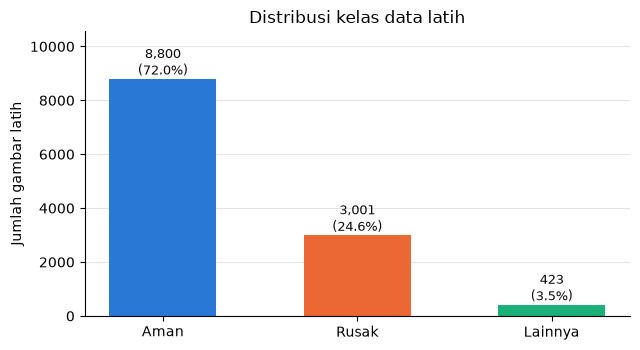

In [12]:
if not CFG.INFERENCE:
    counts = all_df[all_df['split'] == 'train']['label'].value_counts().reindex(CFG.CLASSES)

    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    bars = ax.bar(counts.index, counts.values, width=0.55, color=[CFG.PALETTE[c] for c in counts.index])
    for b, v in zip(bars, counts.values):
        ax.text(b.get_x() + b.get_width() / 2, v, f'{v:,}\n({v / counts.sum():.1%})', ha='center', va='bottom', fontsize=9, color='#0b0b0b')
    ax.set_ylim(0, counts.max() * 1.2)
    ax.set_ylabel('Jumlah gambar latih')
    ax.set_title('Distribusi kelas data latih')
    style_axis(ax)
    fig.tight_layout()
    fig.savefig(CFG.FIG_DIR / 'class_distribution.png', dpi=110)
    plt.show()
else:
    print('INFERENCE = True, distribusi kelas dilewati')

> ### Insights
> Kelas Aman mencakup 72,0% data latih, Rusak 24,6%, dan Lainnya hanya 3,5% atau 423 gambar. Karena *Macro F1* memberi bobot yang sama pada tiap kelas, 423 gambar Lainnya menentukan sepertiga skor. *Sampler* berbobot dan bobot alpha pada *focal loss* diperlukan agar kelas ini tidak tenggelam.

---

## Format, Mode Warna, dan Ukuran

Format asli dibandingkan dengan ekstensi berkas, lalu sebaran sisi terpendek dan rasio aspek dibandingkan antara tiap kelas dan data uji. Perbedaan sebaran antara data latih dan data uji menunjukkan pergeseran distribusi yang harus diantisipasi.

In [13]:
if not CFG.INFERENCE:
    fmt_table = pd.crosstab(all_df['label'], all_df['format']).reindex(GROUP_ORDER)
    mode_table = pd.crosstab(all_df['label'], all_df['mode']).reindex(GROUP_ORDER)
    expected = all_df['ext'].map({'jpg': 'JPEG', 'jpeg': 'JPEG', 'png': 'PNG', 'webp': 'WEBP'})
    mismatch = (all_df['format'] != expected).groupby(all_df['label']).sum().reindex(GROUP_ORDER)

    print('Format asli per grup')
    print(fmt_table.to_string())
    print('\nMode warna per grup')
    print(mode_table.to_string())
    print('\nEkstensi tidak sesuai format asli')
    print(mismatch.to_string())
    print('\nGambar dengan piksel transparan (lebih dari 1 persen luas)')
    print((all_df['transparent_frac'] > 0.01).groupby(all_df['label']).sum().reindex(GROUP_ORDER).to_string())
    print('\nTag orientasi EXIF selain 1')
    print((all_df['exif_orientation'] != 1).groupby(all_df['label']).sum().reindex(GROUP_ORDER).to_string())
    print('\nSisi terpendek (piksel)')
    print(all_df.groupby('label')['short_side'].describe(percentiles=[0.05, 0.5, 0.95]).reindex(GROUP_ORDER).round(0).to_string())
else:
    print('INFERENCE = True, tabel format dan ukuran dilewati')

Format asli per grup
format   AVIF  JPEG  PNG  WEBP
label                         
Aman        1  7915   91   793
Rusak       0  2419    4   578
Lainnya     0   423    0     0
Test        0  2315  145   597

Mode warna per grup
mode     P   RGB  RGBA
label                 
Aman     6  8776    18
Rusak    1  2997     3
Lainnya  0   423     0
Test     3  2953   101

Ekstensi tidak sesuai format asli
label
Aman       811
Rusak      578
Lainnya      0
Test       615

Gambar dengan piksel transparan (lebih dari 1 persen luas)
label
Aman       5
Rusak      1
Lainnya    0
Test       5

Tag orientasi EXIF selain 1
label
Aman       0
Rusak      0
Lainnya    1
Test       1

Sisi terpendek (piksel)
          count   mean    std   min     5%    50%     95%     max
label                                                            
Aman     8800.0  518.0  286.0  37.0  211.0  512.0   776.0  4500.0
Rusak    3001.0  529.0  183.0  46.0  229.0  640.0   675.0  3024.0
Lainnya   423.0  212.0  131.0  47.0   9

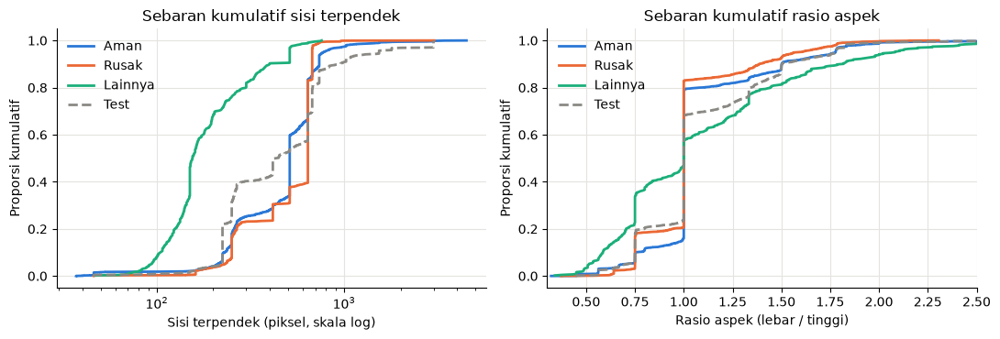

In [14]:
if not CFG.INFERENCE:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for g in GROUP_ORDER:
        d = all_df[all_df['label'] == g]
        style = '--' if g == 'Test' else '-'
        for ax, col in zip(axes, ['short_side', 'aspect']):
            v = np.sort(d[col].values)
            ax.plot(v, np.arange(1, len(v) + 1) / len(v), style, color=CFG.PALETTE[g], linewidth=2, label=g)
    axes[0].set_xscale('log')
    axes[0].set_xlabel('Sisi terpendek (piksel, skala log)')
    axes[0].set_title('Sebaran kumulatif sisi terpendek')
    axes[1].set_xlim(0.3, 2.5)
    axes[1].set_xlabel('Rasio aspek (lebar / tinggi)')
    axes[1].set_title('Sebaran kumulatif rasio aspek')
    for ax in axes:
        ax.set_ylabel('Proporsi kumulatif')
        ax.legend(frameon=False)
        style_axis(ax, grid_axis='both')
    fig.tight_layout()
    fig.savefig(CFG.FIG_DIR / 'size_aspect.png', dpi=110)
    plt.show()
else:
    print('INFERENCE = True, plot ukuran dilewati')

> ### Insights
> Ekstensi berkas tidak dapat dipercaya. Sebanyak 1.388 berkas latih dan 615 berkas uji memiliki isi yang formatnya berbeda dari ekstensinya, sebagian besar WEBP yang diberi nama `.jpg`, sehingga format harus dikenali dari isi berkas. Mode RGBA jauh lebih sering muncul di data uji (101 gambar) daripada di data latih (21 gambar), dan 11 gambar memiliki area yang benar-benar transparan, sehingga penanganan alpha berpengaruh langsung pada prediksi uji. Hanya dua gambar yang membawa tag orientasi EXIF selain 1.
>
> Ukuran gambar sangat beragam, dengan sisi terpendek dari 37 sampai 4.500 piksel. Median sisi terpendek adalah 512 piksel untuk Aman, 640 untuk Rusak, dan hanya 155 untuk Lainnya, sedangkan data uji bermedian 439 piksel dengan ekor panjang sampai 3.000 piksel. Kurva data uji tidak mengikuti kelas mana pun, tanda bahwa komposisi sumber gambarnya berbeda dari data latih.

---

## Jejak Augmentasi Luring

Banyak gambar latih tampak sudah diaugmentasi oleh penyusun *dataset*. Proporsi gambar ber-*noise* dan gambar hasil rotasi dihitung per grup untuk melihat apakah jejak ini merata antar kelas dan apakah data uji memilikinya juga.

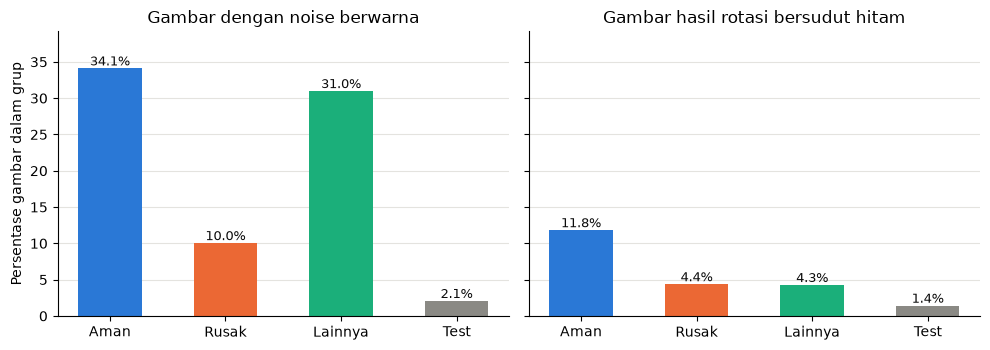

         noisy  rotated  clean
label                         
Aman      34.1     11.8   55.2
Rusak     10.0      4.4   85.8
Lainnya   31.0      4.3   65.0
Test       2.1      1.4   96.6


In [15]:
if not CFG.INFERENCE:
    art = all_df.groupby('label')[['noisy', 'rotated', 'clean']].mean().reindex(GROUP_ORDER)

    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
    for ax, col, title in zip(axes, ['noisy', 'rotated'], ['Gambar dengan noise berwarna', 'Gambar hasil rotasi bersudut hitam']):
        bars = ax.bar(art.index, art[col].values * 100, width=0.55, color=[CFG.PALETTE[g] for g in art.index])
        for b, v in zip(bars, art[col].values * 100):
            ax.text(b.get_x() + b.get_width() / 2, v, f'{v:.1f}%', ha='center', va='bottom', fontsize=9, color='#0b0b0b')
        ax.set_title(title)
        style_axis(ax)
    axes[0].set_ylim(0, art[['noisy', 'rotated']].values.max() * 115)
    axes[0].set_ylabel('Persentase gambar dalam grup')
    fig.tight_layout()
    fig.savefig(CFG.FIG_DIR / 'offline_augmentation.png', dpi=110)
    plt.show()

    print((art * 100).round(1).to_string())
else:
    print('INFERENCE = True, plot jejak augmentasi dilewati')

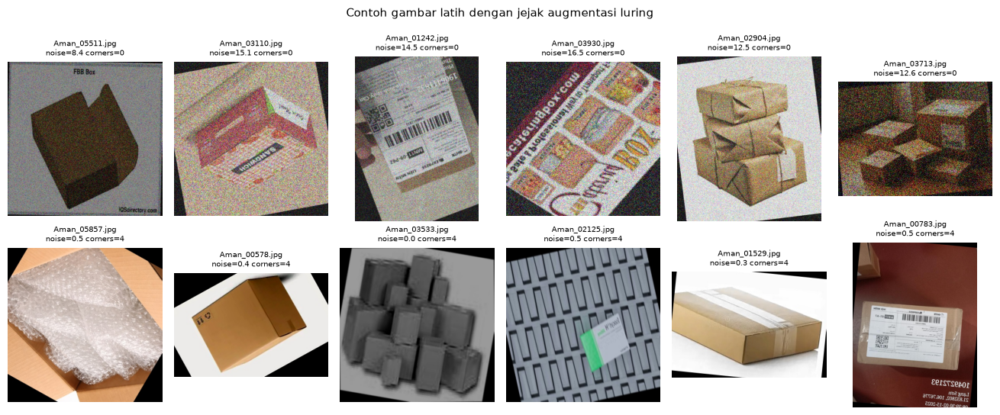

In [16]:
if not CFG.INFERENCE:
    rng = np.random.default_rng(CFG.SEED)
    train_noisy = all_df[(all_df['split'] == 'train') & all_df['noisy']]
    train_rot = all_df[(all_df['split'] == 'train') & all_df['rotated'] & ~all_df['noisy']]
    picks = pd.concat([train_noisy.sample(min(6, len(train_noisy)), random_state=1), train_rot.sample(min(6, len(train_rot)), random_state=1)])
    show_grid(picks['path'].tolist(), [f"{r['name']}\nnoise={r['chroma_noise']:.1f} corners={r['dark_corners']}" for _, r in picks.iterrows()],
              'Contoh gambar latih dengan jejak augmentasi luring', cols=6, save_as='offline_augmentation_examples.png')
else:
    print('INFERENCE = True, contoh jejak augmentasi dilewati')

> ### Insights
> Jejak augmentasi luring tidak merata antar kelas. *Noise* berwarna ditemukan pada 34,1% gambar Aman dan 31,0% gambar Lainnya, tetapi hanya pada 10,0% gambar Rusak. Rotasi bersudut hitam muncul pada 11,8% gambar Aman dan sekitar 4% gambar kelas lain. Model dapat memakai jejak ini sebagai jalan pintas, yaitu menganggap gambar ber-*noise* sebagai Aman dan gambar bersih sebagai Rusak.
>
> Data uji hampir seluruhnya bersih, dengan hanya 2,1% gambar ber-*noise* dan 1,4% gambar hasil rotasi. Jalan pintas tadi tidak berlaku di data uji dan justru menggeser prediksi ke arah Rusak. Karena itu augmentasi latih menerapkan *noise*, rotasi, dan *grayscale* secara acak ke semua kelas, sehingga jejak augmentasi luring tidak bisa dipakai model sebagai penanda kelas.

---

## Duplikasi, Konflik Label, dan Tumpang Tindih dengan Data Uji

Gambar yang *byte*-nya identik dideteksi lewat MD5, sedangkan gambar yang hampir identik dideteksi lewat jarak Hamming dua *perceptual hash* sekaligus. Pasangan dihitung untuk gabungan data latih dan data uji sehingga tiga hal terlihat sekaligus, yaitu duplikat di dalam data latih, gambar sama yang diberi label berbeda, dan gambar uji yang kembarannya ada di data latih.

In [17]:
if not CFG.INFERENCE:
    def to_bits(series):
        return np.stack([np.frombuffer(s.encode(), dtype=np.uint8) - 48 for s in series]).astype(np.float32)

    def near_duplicate_pairs(dh, ph, dh_max, ph_max, chunk=2048):
        d = torch.from_numpy(dh).to(DEVICE)
        p = torch.from_numpy(ph).to(DEVICE)
        d_sum, p_sum = d.sum(1), p.sum(1)
        pairs = []
        for s in range(0, len(d), chunk):
            # hamming(a, b) = |a| + |b| - 2 * a . b for binary vectors
            hd = d_sum[s:s + chunk, None] + d_sum[None, :] - 2 * d[s:s + chunk] @ d.T
            hp = p_sum[s:s + chunk, None] + p_sum[None, :] - 2 * p[s:s + chunk] @ p.T
            idx = ((hd <= dh_max) & (hp <= ph_max)).nonzero()
            i, j = idx[:, 0] + s, idx[:, 1]
            keep = i < j
            pairs.append(torch.stack([i[keep], j[keep]], dim=1).cpu())
        return torch.cat(pairs).numpy()

    pairs = near_duplicate_pairs(to_bits(all_df['dhash']), to_bits(all_df['phash']), CFG.DHASH_MAX_DIST, CFG.PHASH_MAX_DIST)
    is_train = (all_df['split'] == 'train').to_numpy(dtype=bool)
    labels_arr = all_df['label'].to_numpy(dtype=object)

    tr_all = all_df[is_train]
    md5_labels = tr_all.groupby('md5')['label'].agg(lambda s: tuple(sorted(set(s))))
    conflict_md5 = md5_labels[md5_labels.map(len) > 1].index
    test_match = all_df[~is_train]['md5'].map(md5_labels)

    cross = pairs[is_train[pairs[:, 0]] != is_train[pairs[:, 1]]]
    test_with_twin = np.unique(np.where(is_train[cross[:, 0]], cross[:, 1], cross[:, 0]))
    within = pairs[is_train[pairs[:, 0]] & is_train[pairs[:, 1]]]
    conflict_pairs = within[labels_arr[within[:, 0]] != labels_arr[within[:, 1]]]

    print(f'Berkas latih valid                       : {len(tr_all)}')
    print(f'Berkas latih unik (MD5)                  : {tr_all["md5"].nunique()}')
    print(f'Duplikat byte-identik berlebih           : {len(tr_all) - tr_all["md5"].nunique()}')
    print(f'Grup MD5 dengan label bertentangan       : {len(conflict_md5)}')
    print(f'Pasangan hampir identik beda label       : {len(conflict_pairs)}')
    print(f'Gambar uji byte-identik dengan data latih: {test_match.notna().sum()} ({test_match.notna().mean():.1%})')
    print(test_match.dropna().value_counts().to_string())
    print(f'Gambar uji dengan kembaran hampir identik: {len(test_with_twin)} ({len(test_with_twin) / (~is_train).sum():.1%})')
else:
    print('INFERENCE = True, deteksi duplikat dilewati')

Berkas latih valid                       : 12224
Berkas latih unik (MD5)                  : 11571
Duplikat byte-identik berlebih           : 653
Grup MD5 dengan label bertentangan       : 26
Pasangan hampir identik beda label       : 129
Gambar uji byte-identik dengan data latih: 253 (8.3%)
md5
(Aman,)          155
(Rusak,)          96
(Aman, Rusak)      2
Gambar uji dengan kembaran hampir identik: 747 (24.4%)


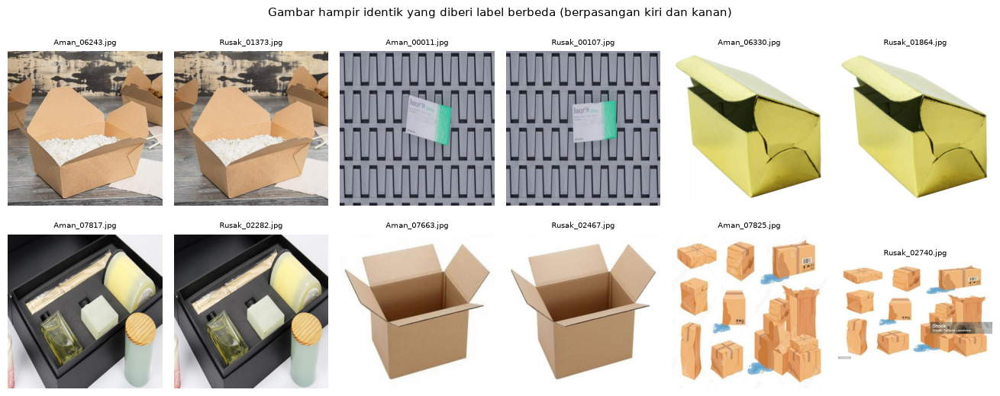

In [18]:
if not CFG.INFERENCE:
    show_pairs = conflict_pairs[rng.permutation(len(conflict_pairs))[:6]] if len(conflict_pairs) else np.zeros((0, 2), dtype=int)
    if len(show_pairs):
        flat = show_pairs.ravel()
        show_grid(all_df['path'].to_numpy()[flat].tolist(), all_df['name'].to_numpy()[flat].tolist(),
                  'Gambar hampir identik yang diberi label berbeda (berpasangan kiri dan kanan)', cols=6, save_as='label_conflicts.png')
else:
    print('INFERENCE = True, contoh konflik label dilewati')

> ### Insights
> Data latih memuat 653 berkas yang *byte*-nya identik dengan berkas lain, dan 26 grup di antaranya diberi label Aman sekaligus Rusak. Secara keseluruhan terdapat 129 pasangan gambar identik atau hampir identik yang labelnya berbeda. Label pada *dataset* ini jelas bising, sehingga *label smoothing* dan pembersihan label lebih aman daripada mempercayai setiap label apa adanya.
>
> Sebanyak 253 gambar uji (8,3%) *byte*-identik dengan gambar latih, dan 747 gambar uji (24,4%) memiliki kembaran hampir identik di data latih. Validasi acak akan membocorkan kembaran semacam ini antar fold dan menghasilkan skor yang terlalu optimistis, sehingga fold dibentuk per grup gambar mirip.

---

## Contoh Gambar per Kelas

Contoh acak dari tiap kelas dan dari data uji ditampilkan untuk melihat isi visual yang harus dipisahkan model.

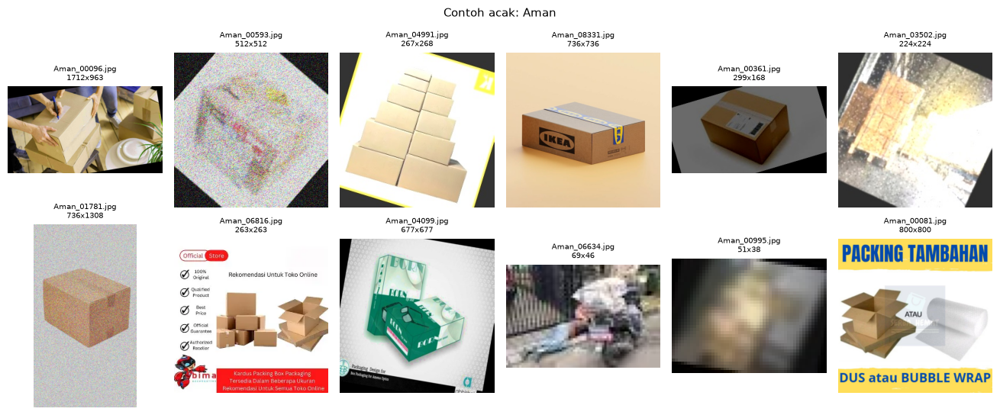

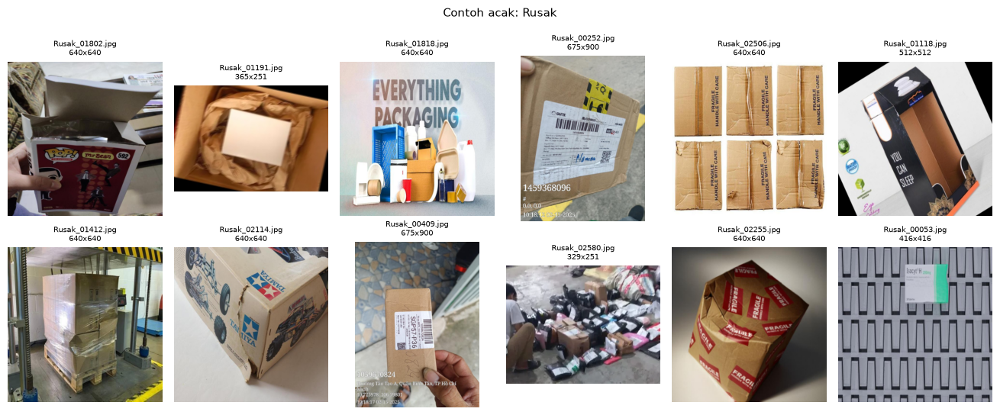

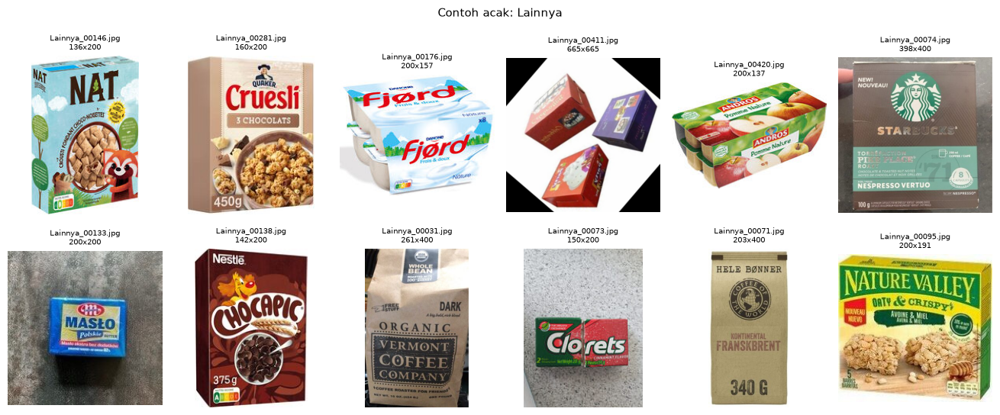

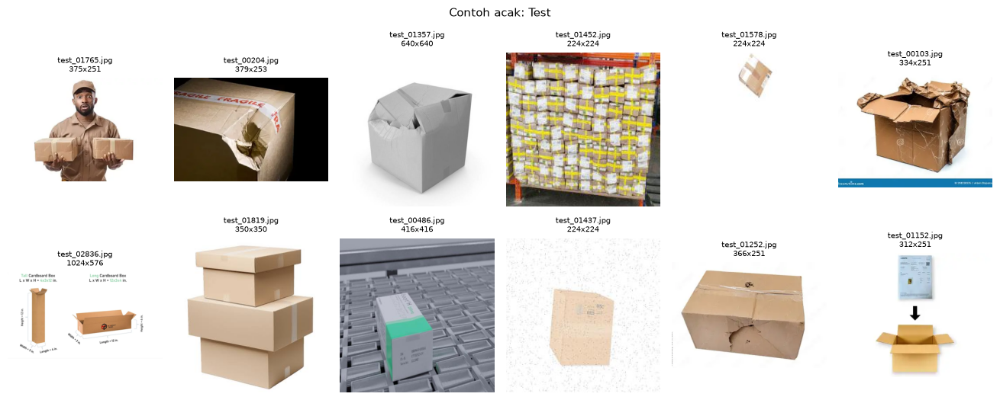

In [19]:
if not CFG.INFERENCE:
    for g in GROUP_ORDER:
        d = all_df[all_df['label'] == g]
        d = d.sample(min(12, len(d)), random_state=CFG.SEED)
        show_grid(d['path'].tolist(), [f"{r['name']}\n{r['width']}x{r['height']}" for _, r in d.iterrows()], f'Contoh acak: {g}', cols=6, save_as=f'samples_{g}.png')
else:
    print('INFERENCE = True, contoh gambar per kelas dilewati')

> ### Insights
> Kelas Aman dan Rusak sama-sama didominasi dus karton dan paket berlabel resi. Pembedanya adalah detail lokal seperti penyok, sobekan, dan lipatan, bukan jenis objeknya, sehingga resolusi masukan 320 piksel dan augmentasi yang tidak membuang area gambar menjadi penting. Kelas Lainnya berisi kemasan produk makanan beresolusi rendah yang tampil sangat berbeda.
>
> Data uji memuat kelompok gambar yang jarang ada di data latih, antara lain foto ponsel beresolusi tinggi berisi paket berbungkus oranye dan gambar dus sintetis berlatar polos. Pergeseran ini menjadi alasan pemakaian *backbone* pra-latih berskala besar yang fiturnya sudah umum, serta augmentasi yang ringan.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Prapemrosesan dan Augmentasi <a name="4"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Justifikasi Augmentasi

Transformasi evaluasi hanya mengubah ukuran gambar menjadi persegi dengan interpolasi bilinear beserta *antialiasing*, lalu menormalkan piksel dengan statistik ImageNet. Cara ini identik dengan *image processor* resmi DINOv3. Seluruh isi gambar dipertahankan karena kerusakan sering berada di tepi paket, sehingga *center crop* tidak dipakai.

Augmentasi latih dibuat ringan:

- **`RandomResizedCrop`** dengan skala minimal 0,6 -- potongan acak mempertahankan minimal 60% luas gambar agar area kerusakan tidak terbuang
- **`RandomHorizontalFlip`** -- kondisi paket tidak berubah oleh pencerminan, dan TTA juga memakai cermin
- **`RandomRotation`** 25 derajat berisi hitam, **`GaussianNoise`**, dan **`RandomGrayscale`** -- menyebarkan jejak augmentasi luring ke semua kelas supaya jejak tersebut tidak lagi menjadi penanda kelas
- **`ColorJitter`** dan **`GaussianBlur`** ringan -- variasi kamera dan pencahayaan antar sumber

---

## Transformasi Training

In [20]:
class GaussianNoise(nn.Module):
    def __init__(self, sigma=(0.03, 0.15), p=0.15):
        super().__init__()
        self.sigma = sigma
        self.p = p

    def forward(self, x):
        if torch.rand(1).item() >= self.p:
            return x
        s = torch.empty(1).uniform_(*self.sigma).item()
        return (x + torch.randn_like(x) * s).clamp_(0.0, 1.0)

def build_train_tf(size, mean, std):
    return v2.Compose([
        v2.RandomResizedCrop(size, scale=(0.6, 1.0), ratio=(3 / 4, 4 / 3), interpolation=InterpolationMode.BILINEAR, antialias=True),
        v2.RandomHorizontalFlip(0.5),
        v2.RandomApply([v2.RandomRotation(25, interpolation=InterpolationMode.BILINEAR, fill=0)], p=0.25),
        v2.RandomApply([v2.ColorJitter(0.2, 0.2, 0.2, 0.02)], p=0.8),
        v2.RandomGrayscale(p=0.05),
        v2.RandomApply([v2.GaussianBlur(5, sigma=(0.3, 1.5))], p=0.1),
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True),
        GaussianNoise(p=0.15),
        v2.Normalize(mean, std),
    ])

TRAIN_TF = build_train_tf(CFG.IMG_SIZE, CFG.MEAN, CFG.STD)

---

## Transformasi Validasi dan Inferensi

Transformasi yang sama dipakai untuk validasi, ekstraksi fitur pembersihan, dan prediksi data uji. Fungsi `denormalize` mengembalikan tensor ternormalisasi ke piksel agar hasil transformasi bisa diperiksa secara visual.

In [21]:
def build_eval_tf(size, mean, std):
    return v2.Compose([
        v2.Resize((size, size), interpolation=InterpolationMode.BILINEAR, antialias=True),
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(mean, std),
    ])

def denormalize(t):
    mean = torch.tensor(CFG.MEAN).view(3, 1, 1)
    std = torch.tensor(CFG.STD).view(3, 1, 1)
    return ((t.cpu() * std + mean).clamp(0, 1) * 255).round().byte().permute(1, 2, 0).numpy()

EVAL_TF = build_eval_tf(CFG.IMG_SIZE, CFG.MEAN, CFG.STD)

---

## Verifikasi Pembaca Gambar

Dua keputusan pembaca gambar diperiksa pada berkas nyata. Baris pertama membandingkan konversi RGB langsung dengan penggabungan alpha di atas latar putih. Baris kedua membandingkan piksel apa adanya dengan hasil penerapan tag orientasi EXIF.

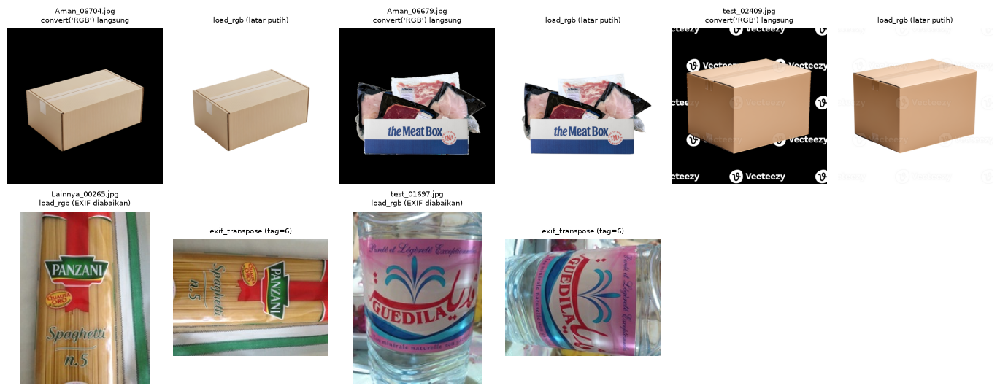

Semua mode warna menghasilkan RGB: True


In [22]:
if not CFG.INFERENCE:
    alpha_rows = all_df[all_df['transparent_frac'] > 0.2].sort_values('transparent_frac', ascending=False).head(3)
    exif_rows = all_df[all_df['exif_orientation'] != 1].head(3)

    n_cols = 2 * max(len(alpha_rows), len(exif_rows), 1)
    fig, axes = plt.subplots(2, n_cols, figsize=(n_cols * 2.3, 5.4), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for k, (_, r) in enumerate(alpha_rows.iterrows()):
        axes[0, 2 * k].imshow(Image.open(r['path']).convert('RGB'))
        axes[0, 2 * k].set_title(f"{r['name']}\nconvert('RGB') langsung", fontsize=7)
        axes[0, 2 * k + 1].imshow(load_rgb(r['path']))
        axes[0, 2 * k + 1].set_title('load_rgb (latar putih)', fontsize=7)
    for k, (_, r) in enumerate(exif_rows.iterrows()):
        axes[1, 2 * k].imshow(load_rgb(r['path']))
        axes[1, 2 * k].set_title(f"{r['name']}\nload_rgb (EXIF diabaikan)", fontsize=7)
        axes[1, 2 * k + 1].imshow(ImageOps.exif_transpose(Image.open(r['path'])).convert('RGB'))
        axes[1, 2 * k + 1].set_title(f"exif_transpose (tag={r['exif_orientation']})", fontsize=7)
    fig.tight_layout()
    fig.savefig(CFG.FIG_DIR / 'preprocess_loader_check.png', dpi=110, bbox_inches='tight')
    plt.show()

    modes_ok = all(load_rgb(p, max_side=256).mode == 'RGB' for p in all_df.groupby('mode').head(5)['path'])
    print('Semua mode warna menghasilkan RGB:', modes_ok)
else:
    print('INFERENCE = True, verifikasi pembaca gambar dilewati')

> ### Insights
> Konversi RGB langsung membuang kanal alpha dan memunculkan piksel tersembunyi di balik area transparan, sehingga latar menjadi hitam dan pada satu gambar uji muncul pola *watermark*. Penggabungan di atas latar putih menghasilkan tampilan yang sama dengan foto produk berlatar putih yang banyak terdapat di data latih. Dua gambar bertag orientasi EXIF 6 ternyata sudah tegak, dan penerapan tag tersebut justru merebahkan gambar, sehingga tag EXIF diabaikan.

---

## Visualisasi Resize dan Augmentasi

Gambar dengan rasio aspek ekstrem ditampilkan sebelum dan sesudah *resize* untuk memastikan objek tetap dikenali. Setelah itu beberapa hasil augmentasi latih ditampilkan berdampingan dengan tampilan evaluasi. Gambar sudah dikembalikan dari tensor ternormalisasi, sehingga yang terlihat adalah persis yang diterima model.

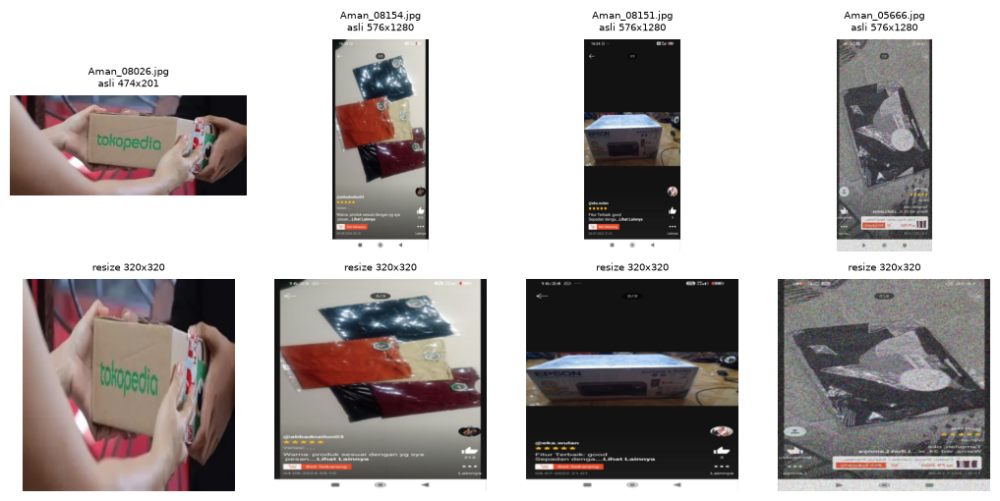

In [23]:
if not CFG.INFERENCE:
    extreme = all_df[(all_df['aspect'] > 2.2) | (all_df['aspect'] < 0.5)]
    extreme = extreme.sample(min(4, len(extreme)), random_state=3)
    if len(extreme):
        fig, axes = plt.subplots(2, len(extreme), figsize=(len(extreme) * 2.6, 5.2), squeeze=False)
        for k, (_, r) in enumerate(extreme.iterrows()):
            im = load_rgb(r['path'], max_side=2 * CFG.IMG_SIZE)
            axes[0, k].imshow(im)
            axes[0, k].set_title(f"{r['name']}\nasli {r['width']}x{r['height']}", fontsize=7)
            axes[1, k].imshow(denormalize(EVAL_TF(im)))
            axes[1, k].set_title(f'resize {CFG.IMG_SIZE}x{CFG.IMG_SIZE}', fontsize=7)
        for ax in axes.ravel():
            ax.axis('off')
        fig.tight_layout()
        fig.savefig(CFG.FIG_DIR / 'preprocess_resize_check.png', dpi=110, bbox_inches='tight')
        plt.show()
else:
    print('INFERENCE = True, visualisasi resize dilewati')

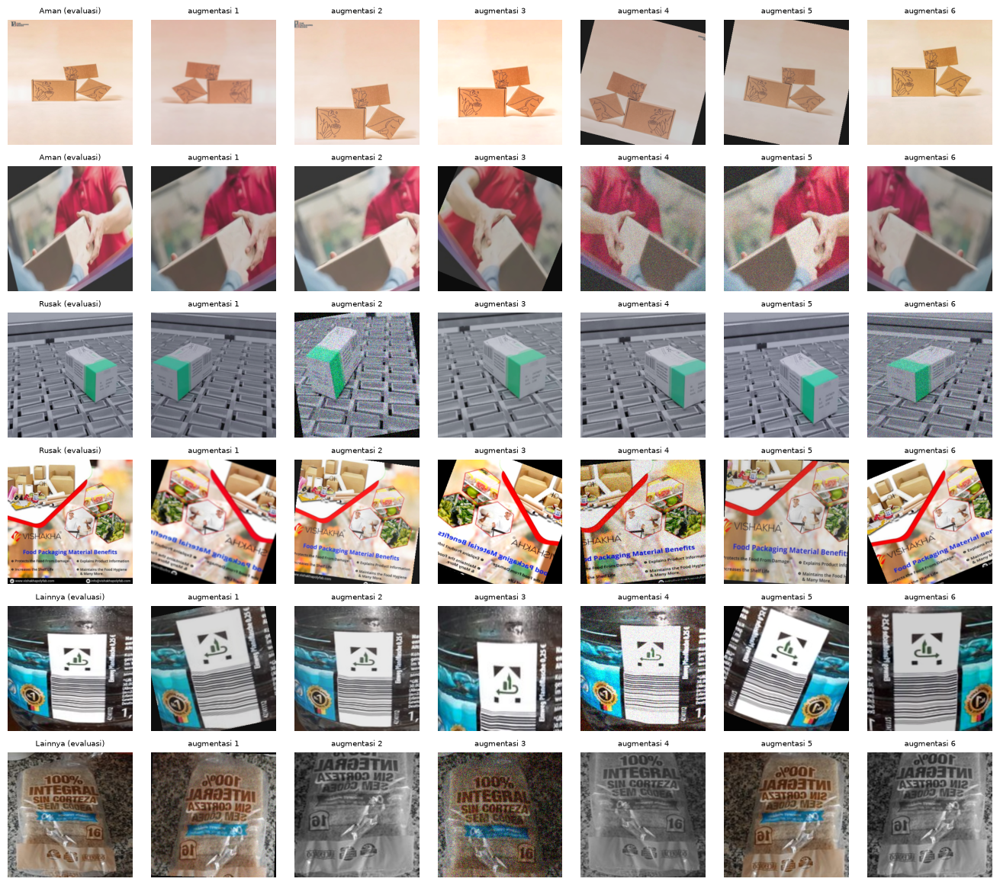

In [24]:
if not CFG.INFERENCE:
    torch.manual_seed(CFG.SEED)
    clean_train = all_df[(all_df['split'] == 'train') & all_df['clean']]
    demo = pd.concat([clean_train[clean_train['label'] == c].sample(2, random_state=7, replace=True) for c in CFG.CLASSES])
    n_aug = 6
    fig, axes = plt.subplots(len(demo), n_aug + 1, figsize=((n_aug + 1) * 1.9, len(demo) * 1.95), squeeze=False)
    for i, (_, r) in enumerate(demo.iterrows()):
        im = load_rgb(r['path'], max_side=2 * CFG.IMG_SIZE)
        axes[i, 0].imshow(denormalize(EVAL_TF(im)))
        axes[i, 0].set_title(f"{r['label']} (evaluasi)", fontsize=7)
        for k in range(n_aug):
            axes[i, k + 1].imshow(denormalize(TRAIN_TF(im)))
            axes[i, k + 1].set_title(f'augmentasi {k + 1}', fontsize=7)
    for ax in axes.ravel():
        ax.axis('off')
    fig.tight_layout()
    fig.savefig(CFG.FIG_DIR / 'preprocess_augmentation_check.png', dpi=110, bbox_inches='tight')
    plt.show()
else:
    print('INFERENCE = True, visualisasi augmentasi dilewati')

---

## Verifikasi Tensor

Tensor hasil transformasi diperiksa bentuk, rentang nilai, dan kebebasannya dari NaN. Tensor evaluasi juga dibandingkan dengan hasil *resize* PIL secara langsung untuk memastikan normalisasi dapat dibalik tanpa selisih.

In [25]:
if not CFG.INFERENCE:
    sample_paths = all_df.sample(min(64, len(all_df)), random_state=CFG.SEED)['path'].tolist()
    eval_batch = torch.stack([EVAL_TF(load_rgb(p, max_side=2 * CFG.IMG_SIZE)) for p in sample_paths])
    train_batch = torch.stack([TRAIN_TF(load_rgb(p, max_side=2 * CFG.IMG_SIZE)) for p in sample_paths])

    lo = min((0 - m) / s for m, s in zip(CFG.MEAN, CFG.STD))
    hi = max((1 - m) / s for m, s in zip(CFG.MEAN, CFG.STD))
    for name, batch in [('eval', eval_batch), ('train', train_batch)]:
        assert batch.shape[1:] == (3, CFG.IMG_SIZE, CFG.IMG_SIZE) and batch.dtype == torch.float32
        assert torch.isfinite(batch).all() and batch.min() >= lo - 1e-4 and batch.max() <= hi + 1e-4
        print(f'{name:5s} shape={tuple(batch.shape)} min={batch.min():.3f} max={batch.max():.3f} mean={batch.mean((0, 2, 3)).numpy().round(3)} std={batch.std((0, 2, 3)).numpy().round(3)}')

    ref_im = load_rgb(sample_paths[0], max_side=2 * CFG.IMG_SIZE)
    ref = np.asarray(ref_im.resize((CFG.IMG_SIZE, CFG.IMG_SIZE), Image.BILINEAR)).astype(int)
    diff = np.abs(ref - denormalize(EVAL_TF(ref_im)).astype(int)).max()
    print(f'Selisih maksimum terhadap resize bilinear PIL: {diff} tingkat keabuan')
    assert diff <= 1
else:
    print('INFERENCE = True, verifikasi tensor dilewati')

eval  shape=(64, 3, 320, 320) min=-2.118 max=2.640 mean=[0.639 0.634 0.694] std=[1.187 1.266 1.335]
train shape=(64, 3, 320, 320) min=-2.118 max=2.640 mean=[0.508 0.495 0.559] std=[1.162 1.236 1.302]
Selisih maksimum terhadap resize bilinear PIL: 0 tingkat keabuan


> ### Insights
> *Resize* langsung ke persegi mempertahankan seluruh isi gambar. Pada rasio aspek ekstrem objek tampak memipih atau melebar, namun kerusakan di tepi paket tetap berada di dalam bingkai, berbeda dengan *center crop* yang membuangnya.
>
> Seluruh hasil augmentasi tetap memperlihatkan objek utama beserta area kerusakannya. Tensor berada pada rentang yang sesuai dengan normalisasi *backbone*, bebas NaN, dan dapat dibalik ke piksel asal tanpa selisih.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pengelompokan Kembaran dan Split Validasi <a name="5"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Temuan audit diterjemahkan menjadi tabel latih dan pembagian validasi yang aman dari kebocoran. Grup gambar mirip diperluas agar mencakup salinan hasil rotasi dan cermin, berkas korup dibuang, duplikat *byte*-identik digabung menjadi satu baris, konflik label diubah menjadi label lunak, dan fold validasi dibentuk per grup. 

## Pengelompokan Ulang Invarian Rotasi dan Cermin

*Perceptual hash* tahan terhadap perubahan ukuran dan kompresi ulang, tetapi tidak terhadap dua operasi yang paling sering dipakai augmentasi luring. Rotasi memindahkan setiap piksel pada kisi pembanding, sehingga hash berubah total, dan pencerminan membalik arah setiap perbandingan. Salinan seperti itu mendapat grup yang berbeda dari sumbernya, lalu salah satunya bisa memvalidasi model yang dilatih pada yang lain.

Tahap ini menutup celah tersebut dalam tiga langkah. Cakram di tengah setiap gambar disampel ulang ke kisi radius kali sudut. Pada koordinat itu rotasi menjadi pergeseran melingkar sepanjang sumbu sudut dan pencerminan menjadi pembalikannya, sehingga magnitudo transformasi Fourier sepanjang sumbu sudut tidak berubah oleh keduanya dan dipakai sebagai deskriptor untuk mengusulkan pasangan. Pasangan hasil pencerminan juga diusulkan langsung dari hash, karena cermin horizontal memetakan *difference hash* ke pembalikan dan inversi tiap barisnya. Setiap usulan lalu diverifikasi dengan korelasi ternormalisasi pada semua pergeseran sudut dan kedua arah cermin, yang dihitung sekaligus lewat satu transformasi Fourier balik. Hanya pasangan dengan korelasi di atas `REGROUP_NCC` yang digabung.

Menggabungkan dua grup yang ternyata bukan duplikat hanya membuat pembagian sedikit lebih kasar, sedangkan gagal menggabungkan duplikat menaruh salinan gambar latih di fold validasi. Karena itu ambang dipilih condong ke arah menggabungkan.

In [26]:
if not CFG.INFERENCE:
    POLAR_R, POLAR_A, POLAR_H = 16, 64, 10
    _rad = (np.arange(POLAR_R) + 0.5) / POLAR_R * 0.97
    _ang = np.arange(POLAR_A) / POLAR_A * 2 * np.pi
    _py = _rad[:, None] * np.sin(_ang[None, :])
    _px = _rad[:, None] * np.cos(_ang[None, :])

    def polar_sample(path, size=96):
        im = load_rgb(path, max_side=3 * size)
        w, h = im.size
        s = max(8, int(min(w, h) * 0.70))
        im = im.crop(((w - s) // 2, (h - s) // 2, (w - s) // 2 + s, (h - s) // 2 + s))
        a = np.asarray(im.resize((size, size), Image.BILINEAR), np.float32) / 255.0
        # nearest-pixel sampling keeps the grid symmetric, so a mirrored or quarter-turned copy lands on the same samples
        yy = np.rint((_py + 1) * 0.5 * (size - 1)).astype(np.int32)
        xx = np.rint((_px + 1) * 0.5 * (size - 1)).astype(np.int32)
        p = a[yy, xx]
        g = p @ np.array([0.299, 0.587, 0.114], np.float32)
        # a three-tap average along the angle axis blunts pixel grain
        g = (np.roll(g, 1, 1) + g + np.roll(g, -1, 1)) / 3.0
        return g, p.mean(1), p.std(1)

    def train_groups(edges):
        e = edges[is_train[edges[:, 0]] & is_train[edges[:, 1]]]
        graph = coo_matrix((np.ones(len(e), dtype=np.int8), (e[:, 0], e[:, 1])), shape=(len(all_df), len(all_df)))
        return connected_components(graph, directed=False)[1]

    def group_stats(component):
        sizes = pd.Series(component[is_train]).value_counts()
        return len(sizes), int(sizes.max()), float(sizes[sizes > 1].sum() / is_train.sum() * 100)

    def test_twins(edges):
        cross = edges[is_train[edges[:, 0]] != is_train[edges[:, 1]]]
        return len(np.unique(np.where(is_train[cross[:, 0]], cross[:, 1], cross[:, 0])))

    REGROUP_PAIRS = np.zeros((0, 2), dtype=np.int64)
    if CFG.USE_INVARIANT_REGROUP:
        n_all = len(all_df)
        with ThreadPoolExecutor(max(4, CFG.NUM_WORKERS)) as ex:
            polar = list(tqdm(ex.map(polar_sample, all_df['path']), total=n_all, desc='polar resample'))
        G = np.stack([p[0] for p in polar])
        ring_mean = np.stack([p[1] for p in polar]).reshape(n_all, -1)
        ring_std = np.stack([p[2] for p in polar]).reshape(n_all, -1)
        del polar

        # a rotation is a circular shift along the angle axis, so |FFT| along that axis ignores it
        mag = np.abs(np.fft.rfft(G - G.mean(2, keepdims=True), axis=2))
        desc = np.concatenate([mag[:, :, :POLAR_H].reshape(n_all, -1), ring_mean * 3, ring_std * 3], axis=1).astype(np.float32)
        desc /= np.linalg.norm(desc, axis=1, keepdims=True) + 1e-8

        Z = G - G.mean((1, 2), keepdims=True)
        Z /= Z.reshape(n_all, -1).std(1).reshape(-1, 1, 1) + 1e-6
        F_fwd = np.fft.rfft(Z, axis=2)
        F_mir = np.fft.rfft(Z[:, :, ::-1], axis=2)

        def best_rotated_ncc(i, j):
            best = -1.0
            for f_j in (F_fwd[j], F_mir[j]):
                # circular cross-correlation over every angle offset = one inverse FFT of the spectral product
                cc = np.fft.irfft(F_fwd[i] * np.conj(f_j), n=POLAR_A, axis=1)
                best = max(best, float(cc.sum(0).max()) / (POLAR_R * POLAR_A))
            return best

        known = set(map(tuple, pairs.tolist()))
        proposed = set()
        topk = int(min(CFG.REGROUP_TOPK, n_all - 1))
        for start in tqdm(range(0, n_all, 512), desc='descriptor candidates'):
            sim = desc[start:start + 512] @ desc.T
            sim[np.arange(len(sim)), start + np.arange(len(sim))] = -1.0
            idx = np.argpartition(-sim, topk, axis=1)[:, :topk]
            val = np.take_along_axis(sim, idx, axis=1)
            rows, cols = np.where(val > CFG.REGROUP_COS)
            for a, b in zip(rows, cols):
                i, j = start + int(a), int(idx[a, b])
                proposed.add((min(i, j), max(i, j)))

        # horizontal mirror of a difference hash = every row reversed and inverted
        bits = to_bits(all_df['dhash'])
        side = int(round(bits.shape[1] ** 0.5))
        mirror_bits = (1 - bits.reshape(n_all, side, side)[:, :, ::-1]).reshape(n_all, -1)
        up_norm = bits.sum(1)
        n_mirror = 0
        for start in tqdm(range(0, n_all, 1024), desc='mirror hashes'):
            blk = mirror_bits[start:start + 1024]
            dist = blk.sum(1)[:, None] + up_norm[None, :] - 2.0 * (blk @ bits.T)
            rows, cols = np.where(dist <= CFG.DHASH_MAX_DIST)
            for a, b in zip(rows + start, cols):
                i, j = int(a), int(b)
                if i != j:
                    proposed.add((min(i, j), max(i, j)))
                    n_mirror += 1

        candidates = sorted(proposed - known)
        verified = [(i, j) for i, j in tqdm(candidates, desc='verify') if best_rotated_ncc(i, j) > CFG.REGROUP_NCC]
        if verified:
            REGROUP_PAIRS = np.array(verified, dtype=np.int64)

        before = train_groups(pairs)
        after = train_groups(np.concatenate([pairs, REGROUP_PAIRS]))
        b_n, b_max, b_multi = group_stats(before)
        a_n, a_max, a_multi = group_stats(after)
        print(f'Usulan di luar pasangan hash          : {len(candidates):,}')
        print(f'Lolos verifikasi (NCC > {CFG.REGROUP_NCC})       : {len(verified):,}')
        print()
        print(f'{"":<34}{"hash saja":>12}{"invarian":>12}')
        print(f'{"Jumlah grup latih":<34}{b_n:>12,}{a_n:>12,}')
        print(f'{"Grup terbesar":<34}{b_max:>12,}{a_max:>12,}')
        print(f'{"% gambar latih di grup berisi >1":<34}{b_multi:>12.1f}{a_multi:>12.1f}')
        print(f'{"Gambar uji dengan kembaran latih":<34}{test_twins(pairs):>12,}{test_twins(np.concatenate([pairs, REGROUP_PAIRS])):>12,}')
        del G, Z, mag, desc, F_fwd, F_mir, bits, mirror_bits
    else:
        print('Pengelompokan ulang invarian dimatikan (CFG.USE_INVARIANT_REGROUP)')
else:
    print('INFERENCE = True, pengelompokan ulang invarian dilewati')

polar resample:   0%|          | 0/15281 [00:00<?, ?it/s]

descriptor candidates:   0%|          | 0/30 [00:00<?, ?it/s]

mirror hashes:   0%|          | 0/15 [00:00<?, ?it/s]

verify:   0%|          | 0/106168 [00:00<?, ?it/s]

Usulan di luar pasangan hash          : 106,168
Lolos verifikasi (NCC > 0.93)       : 7,769

                                     hash saja    invarian
Jumlah grup latih                       10,464       7,924
Grup terbesar                               11          18
% gambar latih di grup berisi >1          24.1        54.6
Gambar uji dengan kembaran latih           747       1,672


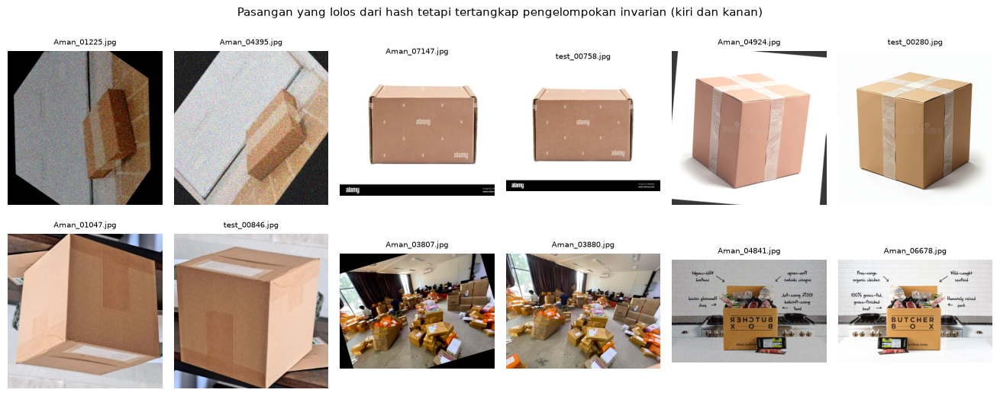

In [27]:
if not CFG.INFERENCE:
    if len(REGROUP_PAIRS):
        show = REGROUP_PAIRS[np.random.default_rng(CFG.SEED).permutation(len(REGROUP_PAIRS))[:6]].ravel()
        show_grid(all_df['path'].to_numpy()[show].tolist(), all_df['name'].to_numpy()[show].tolist(),
                  'Pasangan yang lolos dari hash tetapi tertangkap pengelompokan invarian (kiri dan kanan)', cols=6, save_as='regroup_pairs.png')
else:
    print('INFERENCE = True, contoh pasangan invarian dilewati')

> ### Insights
> Pengelompokan invarian menemukan 7.769 pasangan yang tidak tertangkap hash. Jumlah grup latih turun dari 10.464 menjadi 7.924, dan porsi gambar latih yang punya kembaran naik dari 24,1% menjadi 54,6%. Lebih dari separuh data latih ternyata salinan dari gambar lain, sehingga pembagian fold berbasis hash saja masih membocorkan banyak salinan hasil rotasi, cermin, dan *noise* ke fold validasi.
>
> Ambang `REGROUP_NCC = 0.93` dipilih dari uji terpisah pada *dataset* ini. Pada salinan buatan dari 300 gambar latih, ambang tersebut menangkap sekitar 95% salinan hasil rotasi atau cermin dan 88% salinan hasil rotasi sekaligus *noise*. Pada ambang 0,90 terbentuk grup berisi 51 gambar yang tidak berkaitan, sedangkan pada 0,93 grup terbesar berisi 18 gambar. Salinan hasil rotasi yang kanvasnya diperbesar tidak tertangkap oleh metode ini.

---

## Penanganan Duplikat dan Label Lunak

Setiap grup MD5 disisakan satu berkas. Targetnya adalah rata-rata *one-hot* seluruh anggota grup, sehingga gambar yang muncul di dua kelas mendapat target 0,5 dan 0,5. Baris berlabel lunak ini dibuang oleh aturan pembersihan pertama pada bagian 7.

In [28]:
if not CFG.INFERENCE:
    tr_valid = all_df[all_df['split'] == 'train'].copy()
    onehot = pd.DataFrame(np.eye(NUM_CLASSES, dtype=np.float32)[tr_valid['label'].map(CLASS_TO_ID).values], index=tr_valid.index)
    soft = onehot.groupby(tr_valid['md5']).transform('mean')

    # connected components over hash pairs and rotation/mirror-verified pairs give the leakage-safe groups
    component = train_groups(np.concatenate([pairs, REGROUP_PAIRS]))

    keep = ~tr_valid['md5'].duplicated()
    train_df = tr_valid[keep].copy()
    train_df['group'] = component[train_df.index.to_numpy()]
    SOFT_TARGETS = soft[keep].to_numpy(dtype=np.float32)
    train_df['y'] = SOFT_TARGETS.argmax(1)
    train_df = train_df.reset_index(drop=True)

    test_df = all_df[all_df['split'] == 'test'].reset_index(drop=True)

    print(f'Baris latih setelah deduplikasi : {len(train_df)} (dari {len(tr_valid)})')
    print(f'Baris dengan label lunak        : {(SOFT_TARGETS.max(1) < 1).sum()}')
    print(f'Jumlah grup                     : {train_df["group"].nunique()}')
else:
    print('INFERENCE = True, deduplikasi dilewati')

Baris latih setelah deduplikasi : 11571 (dari 12224)
Baris dengan label lunak        : 26
Jumlah grup                     : 7924


---

## Fold Validasi dan Bobot Kelas

`StratifiedGroupKFold` menjaga proporsi kelas tiap fold sekaligus memastikan satu grup gambar mirip tidak terbelah antara data latih dan validasi. Bobot kelas memakai akar dari kebalikan frekuensi. Pilihan ini menaikkan pengaruh kelas Lainnya tanpa membuat *loss* didominasi oleh 423 gambar saja. Bobot yang sama dihitung ulang dari data bersih oleh *sampler* dan *focal loss* pada bagian 8.

In [29]:
if not CFG.INFERENCE:
    train_df['fold'] = -1
    sgkf = StratifiedGroupKFold(n_splits=CFG.N_FOLDS, shuffle=True, random_state=CFG.SEED)
    for fold, (_, va_idx) in enumerate(sgkf.split(train_df, train_df['y'], train_df['group'])):
        train_df.loc[va_idx, 'fold'] = fold

    class_counts = np.bincount(train_df['y'], minlength=NUM_CLASSES)
    # w_c = sqrt(N / (K * n_c)), rescaled to mean 1
    class_w = np.sqrt(class_counts.sum() / (NUM_CLASSES * class_counts))
    class_w = class_w / class_w.mean()

    fold_table = pd.crosstab(train_df['fold'], train_df['label']).reindex(columns=CFG.CLASSES)
    fold_table['clean_share'] = train_df.groupby('fold')['clean'].mean().round(3)
    print(fold_table.to_string())
    print('\nBobot kelas:', {c: round(float(w), 3) for c, w in zip(CFG.CLASSES, class_w)})
    print('Jumlah baris berjejak augmentasi luring:', int((~train_df['clean']).sum()))
else:
    print('INFERENCE = True, pembentukan fold dilewati')

label  Aman  Rusak  Lainnya  clean_share
fold                                    
0      1706    524       85        0.618
1      1706    523       85        0.615
2      1707    523       84        0.587
3      1707    523       84        0.618
4      1706    523       85        0.616

Bobot kelas: {'Aman': 0.411, 'Rusak': 0.742, 'Lainnya': 1.846}
Jumlah baris berjejak augmentasi luring: 4503


> ### Insights
> Deduplikasi menyisakan 11.571 baris dari 12.224 berkas latih, dengan 26 baris berlabel lunak dan 7.924 grup gambar mirip. Setiap fold memuat proporsi kelas yang hampir sama dengan 84 sampai 85 gambar Lainnya. Jumlah sekecil itu membuat F1 kelas Lainnya per fold mudah berfluktuasi, sehingga skor satu fold perlu dibaca dengan hati-hati.
>
> Sebanyak 4.503 baris berjejak augmentasi luring tidak diberi bobot khusus pada pelatihan. Bias yang mungkin ditimbulkan jejak tersebut ditangani oleh augmentasi latih yang menyebarkan jejak ke semua kelas dan oleh pembersihan sumber pada bagian 7.

---

## Kelas Dataset dan DataLoader

Kelas `PackageDataset` membaca gambar dengan `load_rgb` lalu menerapkan transformasi yang diberikan. Gambar lebih dulu diperkecil sampai sisi terpanjang `2 * IMG_SIZE` agar pembacaan JPEG besar tetap cepat, dan langkah yang sama berlaku untuk data latih, validasi, dan uji.

In [30]:
class PackageDataset(Dataset):
    def __init__(self, paths, transform, targets=None):
        self.paths = list(paths)
        self.transform = transform
        self.targets = None if targets is None else np.asarray(targets, dtype=np.int64)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        x = self.transform(load_rgb(self.paths[i], max_side=2 * CFG.IMG_SIZE))
        if self.targets is None:
            return x
        return x, torch.tensor(self.targets[i], dtype=torch.long)

def build_sampler(y, seed):
    counts = np.bincount(y, minlength=NUM_CLASSES)
    weights = counts[y].astype(np.float64) ** -CFG.SAMPLER_POWER
    generator = torch.Generator()
    generator.manual_seed(seed)
    return WeightedRandomSampler(torch.DoubleTensor(weights), num_samples=len(weights), replacement=True, generator=generator)

def make_loader(paths, targets, train):
    timeout = CFG.LOADER_TIMEOUT if CFG.NUM_WORKERS > 0 else 0
    persistent = CFG.NUM_WORKERS > 0
    if train:
        ds = PackageDataset(paths, TRAIN_TF, targets)
        if CFG.SAMPLER_POWER > 0:
            sampler = build_sampler(np.asarray(targets), CFG.SEED)
            return DataLoader(ds, batch_size=CFG.BATCH_SIZE, sampler=sampler, num_workers=CFG.NUM_WORKERS, pin_memory=True, drop_last=True, persistent_workers=persistent, timeout=timeout)
        return DataLoader(ds, batch_size=CFG.BATCH_SIZE, shuffle=True, num_workers=CFG.NUM_WORKERS, pin_memory=True, drop_last=True, persistent_workers=persistent, timeout=timeout)
    ds = PackageDataset(paths, EVAL_TF, targets)
    return DataLoader(ds, batch_size=CFG.EVAL_BATCH_SIZE, shuffle=False, num_workers=CFG.NUM_WORKERS, pin_memory=False, persistent_workers=persistent, timeout=timeout)

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pemodelan <a name="6"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Arsitektur yang digunakan menggabungkan *backbone* DINOv3 ViT-7B/16 yang sebagian besar dibekukan dengan *head* klasifikasi yang dapat dilatih. Pendekatan ini memanfaatkan representasi fitur yang sudah dipelajari DINOv3 dari 1,689 miliar gambar, sekaligus menjaga kebutuhan memori karena hanya enam dari 40 blok yang diperbarui. Model dibangun satu kali dan dipakai di seluruh sisa *notebook*: sebagai pengekstrak fitur beku untuk pembersihan data di bagian 7, sebagai model yang dilatih pada tiap fold dan pada pelatihan ulang di bagian 8, dan sebagai wadah *checkpoint* model akhir saat inferensi di bagian 9.

## Metrik

Metrik utama adalah *Macro F1-score*, yang menghitung F1 untuk tiap kelas lalu merata-ratakannya tanpa bobot. Metrik ini sesuai karena kelas Lainnya hanya 3,5% dari data latih namun menyumbang sepertiga nilai akhir, sehingga kesalahan pada kelas minoritas sangat mahal.

$$F1_c = \frac{2 \cdot \text{Precision}_c \cdot \text{Recall}_c}{\text{Precision}_c + \text{Recall}_c}\qquad \text{Macro F1} = \frac{1}{C} \sum_{c=1}^{C} F1_c$$

In [31]:
def macro_f1(y_true, y_pred):
    return float(f1_score(y_true, y_pred, average='macro', labels=list(range(NUM_CLASSES)), zero_division=0))

---

## Loss dan Head

*Loss* yang dipakai adalah *focal loss* dengan *label smoothing* dan bobot kelas alpha. *Focal loss* mengecilkan kontribusi contoh yang sudah mudah sehingga gradien terpusat pada contoh sulit (Lin dkk., 2017), sedangkan *label smoothing* menahan model agar tidak terlalu percaya pada label yang bising. *Head* *multi-sample dropout* menerapkan beberapa topeng *dropout* pada fitur yang sama lalu merata-ratakan logitnya (Inoue, 2019). *Dropout* hanya aktif saat latih, sehingga prediksi evaluasi tetap deterministik.

In [32]:
class FocalLossWithSmoothing(nn.Module):
    def __init__(self, num_classes, alpha, gamma, smoothing):
        super().__init__()
        self.gamma = gamma
        self.smoothing = smoothing
        self.num_classes = num_classes
        self.alpha = alpha

    def forward(self, inputs, targets):
        with torch.no_grad():
            true_dist = torch.zeros_like(inputs)
            true_dist.fill_(self.smoothing / (self.num_classes - 1))
            true_dist.scatter_(1, targets.unsqueeze(1), 1.0 - self.smoothing)
        log_p = F.log_softmax(inputs, dim=-1)
        p = log_p.exp()
        focal_weight = (1.0 - p).pow(self.gamma) * self.alpha[targets].view(-1, 1)
        return (-focal_weight * true_dist * log_p).sum(dim=-1).mean()

class MultiSampleDropoutLinearHead(nn.Module):
    def __init__(self, input_dim, num_classes, dropout_p, samples):
        super().__init__()
        self.norm = nn.LayerNorm(input_dim)
        self.dropout = nn.Dropout(dropout_p)
        self.fc = nn.Linear(input_dim, num_classes)
        self.samples = samples

    def forward(self, features):
        features = self.norm(features)
        logits = [self.fc(self.dropout(features)) for _ in range(self.samples)]
        return torch.stack(logits, dim=0).mean(dim=0)

---

## Arsitektur Model

Token CLS merangkum representasi global gambar, sementara rata-rata *patch token* menangkap detail lokal seperti penyok dan sobekan. Keduanya digabungkan sebelum masuk ke *head*, sehingga fitur akhir berdimensi 2 x 4096. DINOv3 menyertakan 4 *register token* setelah token CLS (Darcet dkk., 2024). Pada `last_hidden_state`, indeks 0 adalah CLS, indeks 1 sampai 4 adalah *register token*, dan indeks 5 ke atas adalah *patch token*. Susunan ini diperiksa dengan *assert* pada uji coba di akhir sel.

Daftar blok dicari sebagai `ModuleList` sepanjang `num_hidden_layers`, bukan lewat nama atribut, karena nama modul berbeda antar versi *transformers*. Seluruh *backbone* dibekukan, lalu enam blok terakhir dan LayerNorm di luar daftar blok (norm akhir) dibuka.

In [33]:
def find_blocks(backbone):
    n_layers = backbone.config.num_hidden_layers
    for name, module in backbone.named_modules():
        if isinstance(module, nn.ModuleList) and len(module) == n_layers:
            return name, module
    raise RuntimeError('daftar blok transformer tidak ditemukan')

def load_backbone():
    token = os.environ.get('HF_TOKEN') or None
    kwargs = {'attn_implementation': CFG.ATTN_IMPLEMENTATION, 'token': token}
    dtype_kw = 'dtype' if int(transformers.__version__.split('.')[0]) >= 5 else 'torch_dtype'
    kwargs[dtype_kw] = CFG.BACKBONE_DTYPE if DEVICE.type == 'cuda' else torch.float32
    backbone = AutoModel.from_pretrained(CFG.MODEL_ID, **kwargs)
    for module in backbone.modules():
        if hasattr(module, 'inv_freq') and hasattr(module, 'base') and hasattr(module, 'head_dim'):
            module.inv_freq = 1 / module.base ** torch.arange(0, 1, 4 / module.head_dim, dtype=torch.float32)
    backbone.requires_grad_(False)
    block_name, blocks = find_blocks(backbone)
    tunable = list(blocks)[-CFG.UNFREEZE_LAST_N:] if CFG.UNFREEZE_LAST_N > 0 else []
    tunable += [m for n, m in backbone.named_modules() if isinstance(m, nn.LayerNorm) and not n.startswith(block_name + '.')]
    # trained weights are stored in float32: an AdamW step at this learning rate is smaller than the bfloat16 grid
    for module in tunable:
        module.float()
    if CFG.GRAD_CHECKPOINTING:
        backbone.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant': False})
    return backbone, block_name, blocks, tunable

class DINOClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone, self.block_name, blocks, tunable = load_backbone()
        self.n_blocks = len(blocks)
        self.num_prefix = 1 + getattr(self.backbone.config, 'num_register_tokens', 0)
        self.feature_dropout = nn.Dropout(CFG.FEATURE_DROPOUT_P)
        feature_dim = self.backbone.config.hidden_size * 2
        self.head = MultiSampleDropoutLinearHead(feature_dim, NUM_CLASSES, CFG.HEAD_DROPOUT_P, CFG.MSD_SAMPLES)
        tunable_ids = {id(p) for m in tunable for p in m.parameters()}
        self.tunable_names = [n for n, p in self.named_parameters() if id(p) in tunable_ids]
        self.save_names = self.tunable_names + [n for n, _ in self.named_parameters() if not n.startswith('backbone.')]

    def features(self, x):
        tokens = self.backbone(pixel_values=x).last_hidden_state
        cls_token = tokens[:, 0, :].float()
        patch_mean = tokens[:, self.num_prefix:, :].float().mean(dim=1)
        return torch.cat([cls_token, patch_mean], dim=1)

    def forward(self, x):
        return self.head(self.feature_dropout(self.features(x)))

def trainable_state(model):
    params = dict(model.named_parameters())
    return {n: params[n].detach().cpu().clone() for n in model.save_names}

def load_trainable(model, state):
    missing, unexpected = model.load_state_dict(state, strict=False)
    assert not unexpected, f'kunci asing: {unexpected[:5]}'
    assert not set(model.save_names) & set(missing), 'parameter terlatih tidak ada di state'

seed_everything(CFG.SEED)
model = DINOClassifier().to(DEVICE).eval()
PRETRAINED_STATE = None if CFG.INFERENCE else trainable_state(model)

n_params = sum(p.numel() for p in model.backbone.parameters()) / 1e6
n_tunable = sum(p.numel() for n, p in model.named_parameters() if n in set(model.tunable_names)) / 1e6
print(f'Backbone: {CFG.MODEL_ID} | parameter: {n_params:,.0f} M | blok: {model.n_blocks} ({model.block_name})')
print(f'Dibuka: {CFG.UNFREEZE_LAST_N} blok terakhir + norm akhir = {n_tunable:,.0f} M parameter float32')
print(f'Token awalan: {model.num_prefix} | dimensi fitur: {model.backbone.config.hidden_size * 2}')

with torch.no_grad(), autocast_ctx():
    dummy = torch.zeros(2, 3, CFG.IMG_SIZE, CFG.IMG_SIZE, device=DEVICE)
    seq = model.backbone(pixel_values=dummy).last_hidden_state
    smoke = model(dummy)
n_patches = (CFG.IMG_SIZE // model.backbone.config.patch_size) ** 2
assert seq.shape[1] == model.num_prefix + n_patches, 'susunan token berbeda dari CLS + register + patch'
assert smoke.shape == (2, NUM_CLASSES)
print(f'Urutan token: {tuple(seq.shape)} ({model.num_prefix} awalan + {n_patches} patch) | bentuk logit: {tuple(smoke.shape)}')
del seq, smoke, dummy
torch.cuda.empty_cache()

config.json:   0%|          | 0.00/746 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/48.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/687 [00:00<?, ?it/s]

Backbone: facebook/dinov3-vit7b16-pretrain-lvd1689m | parameter: 6,716 M | blok: 40 (model.layer)
Dibuka: 6 blok terakhir + norm akhir = 1,007 M parameter float32
Token awalan: 5 | dimensi fitur: 8192
Urutan token: (2, 405, 4096) (5 awalan + 400 patch) | bentuk logit: (2, 3)


---

## Inspeksi Arsitektur Backbone

In [34]:
print('=== backbone named_children ===')
for n, m in model.backbone.named_children():
    print(f'  {n}: {type(m).__name__}')

last_block = model.backbone.get_submodule(model.block_name)[-1]
print(f'\n=== blok terakhir ({model.block_name}[-1]): {type(last_block).__name__} ===')
for n, m in last_block.named_children():
    print(f'  {n}: {type(m).__name__}')

tunable_set = set(model.tunable_names)
param_table = pd.DataFrame([
    {'kelompok': 'dibuka' if n in tunable_set else ('head' if not n.startswith('backbone.') else 'beku'), 'dtype': str(p.dtype), 'jumlah': p.numel()}
    for n, p in model.named_parameters()
])
print('\n=== parameter per kelompok (juta) ===')
print((param_table.groupby(['kelompok', 'dtype'])['jumlah'].sum() / 1e6).round(1).to_string())
assert all(p.dtype == torch.float32 for n, p in model.named_parameters() if n in tunable_set), 'ada parameter dibuka yang bukan float32'

processor = AutoImageProcessor.from_pretrained(CFG.MODEL_ID, token=os.environ.get('HF_TOKEN') or None)
print(f'\nimage_mean processor: {tuple(processor.image_mean)} | dipakai: {CFG.MEAN}')
print(f'image_std  processor: {tuple(processor.image_std)} | dipakai: {CFG.STD}')
assert np.allclose(processor.image_mean, CFG.MEAN, atol=1e-3) and np.allclose(processor.image_std, CFG.STD, atol=1e-3), 'normalisasi DINOv3 7B berbeda dari normalisasi asrun'

=== backbone named_children ===
  embeddings: DINOv3ViTEmbeddings
  rope_embeddings: DINOv3ViTRopePositionEmbedding
  model: DINOv3ViTEncoder
  norm: LayerNorm

=== blok terakhir (model.layer[-1]): DINOv3ViTLayer ===
  norm1: LayerNorm
  attention: DINOv3ViTAttention
  layer_scale1: DINOv3ViTLayerScale
  drop_path: Identity
  norm2: LayerNorm
  mlp: DINOv3ViTGatedMLP
  layer_scale2: DINOv3ViTLayerScale

=== parameter per kelompok (juta) ===
kelompok  dtype         
beku      torch.bfloat16    5709.1
dibuka    torch.float32     1006.9
head      torch.float32        0.0


preprocessor_config.json:   0%|          | 0.00/585 [00:00<?, ?B/s]


image_mean processor: (0.485, 0.456, 0.406) | dipakai: (0.485, 0.456, 0.406)
image_std  processor: (0.229, 0.224, 0.225) | dipakai: (0.229, 0.224, 0.225)


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pembersihan Data <a name="7"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Bagian ini mengurangi label yang tidak sesuai dengan isi gambar sebelum pelatihan. Tiga aturan dijalankan berurutan dan setiap aturan hanya menyentuh baris yang belum diubah oleh aturan sebelumnya. Hasil akhirnya dicatat per berkas di `cleaning_log.csv` sehingga setiap keputusan dapat ditelusuri.

In [35]:
if not CFG.INFERENCE:
    train_df['label_orig'] = train_df['label']
    train_df['y_clean'] = train_df['y']
    train_df['status'] = 'simpan'
    train_df['source'] = train_df['width'].astype(str) + 'x' + train_df['height'].astype(str)
    test_df['source'] = test_df['width'].astype(str) + 'x' + test_df['height'].astype(str)

    print(train_df['status'].value_counts().to_string())
else:
    print('INFERENCE = True, inisialisasi status pembersihan dilewati')

status
simpan    11571


## Aturan 1: Konflik MD5

Gambar yang *byte*-nya identik tetapi muncul di dua kelas tidak mungkin benar di kedua kelas. Pada bagian 5 baris seperti ini sudah digabung menjadi satu baris berlabel lunak. Baris tersebut dibuang di sini karena tidak ada alasan memilih salah satu label.

In [36]:
if not CFG.INFERENCE:
    if CFG.CLEAN_MD5_CONFLICT:
        conflict_mask = (SOFT_TARGETS.max(axis=1) < 1).copy()
        train_df.loc[conflict_mask, 'status'] = 'buang_konflik_md5'
        print(train_df.loc[conflict_mask, 'label'].value_counts().to_string())
    print(train_df['status'].value_counts().to_string())
else:
    print('INFERENCE = True, aturan 1 dilewati')

label
Aman    26
status
simpan               11545
buang_konflik_md5       26


---

## Aturan 2: Profil Sumber

Gambar dari satu sumber biasanya memiliki ukuran piksel yang sama, sehingga ukuran dipakai sebagai penanda sumber. Tabel berikut membandingkan jumlah gambar latih per kelas dengan jumlah gambar uji untuk sumber terbesar di data uji. Sumber dengan gambar uji banyak tetapi label latih yang bercampur adalah yang paling berisiko menggeser prediksi.

In [37]:
if not CFG.INFERENCE:
    source_table = pd.crosstab(train_df['source'], train_df['label']).reindex(columns=CFG.CLASSES, fill_value=0)
    source_table['uji'] = test_df['source'].value_counts().reindex(source_table.index).fillna(0).astype(int)
    only_test = test_df['source'].value_counts()
    only_test = only_test[~only_test.index.isin(source_table.index)]
    source_table = pd.concat([source_table, pd.DataFrame({c: 0 for c in CFG.CLASSES} | {'uji': only_test.values}, index=only_test.index)])
    source_table = source_table.sort_values('uji', ascending=False)
    source_table.to_csv(CFG.OUTPUT_DIR / 'source_table.csv')
    print(source_table.head(15).to_string())
else:
    print('INFERENCE = True, tabel sumber dilewati')

           Aman  Rusak  Lainnya  uji
source                              
224x224     253      0        0  520
640x640    1315    930        2  347
675x900     108    391        0  280
416x416      87    211        0  193
736x736     121      1        0   55
3000x4000    11      0        0   55
512x512    2259    205       28   45
267x267      83     26        0   40
2816x1536    20      0        0   40
4000x3000     9      0        0   37
736x981      57      2        0   32
736x1308     39      0        0   30
679x900      11     29        0   30
2390x1792     6      0        0   28
1536x1024    11      0        0   23


Empat sumber yang gambarnya jelas satu kelas dicek secara visual. Tiap kotak menampilkan sampel acak gambar latih yang berlabel Rusak dari sumber tersebut, bersama nama berkasnya.

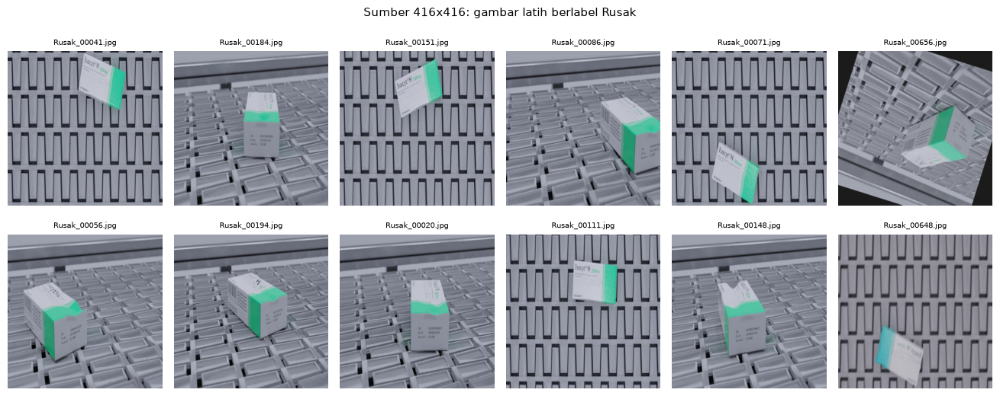

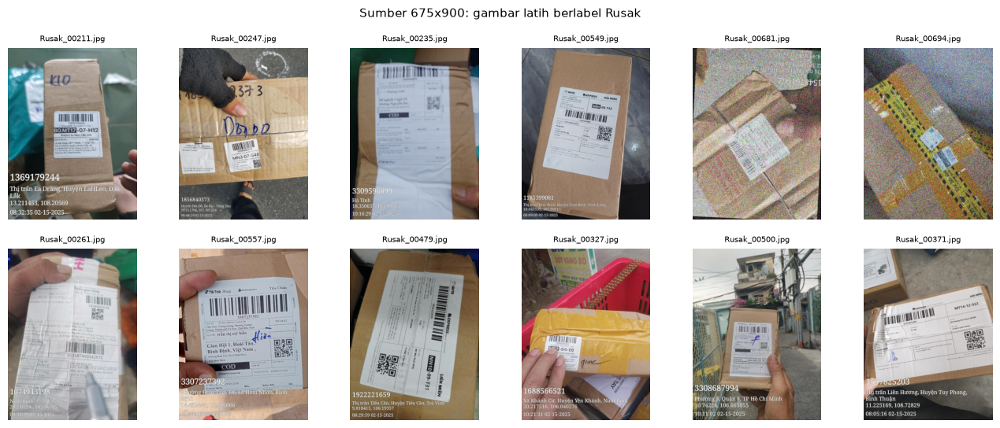

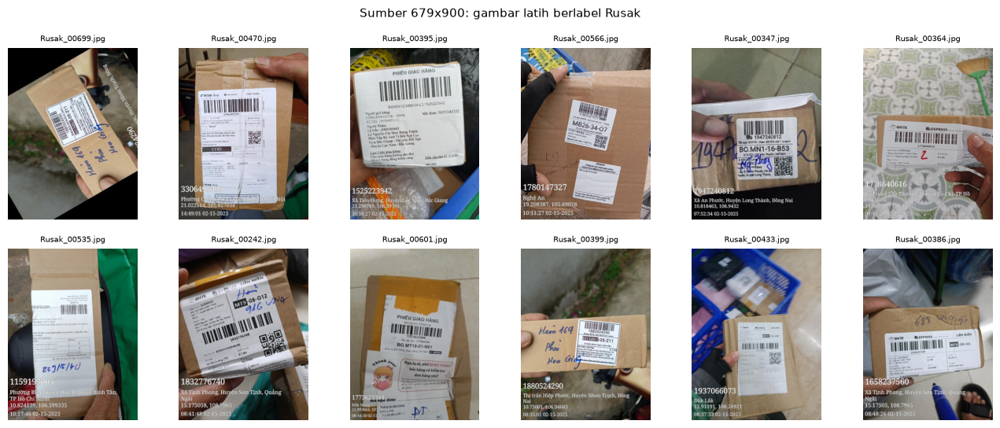

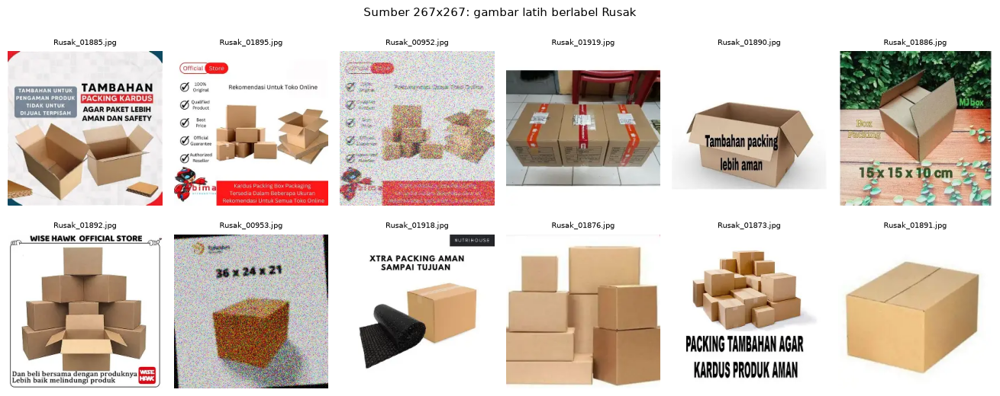

In [38]:
if not CFG.INFERENCE:
    SOURCE_PROFILE = {
        '416x416': 'Aman',
        '675x900': 'Aman',
        '679x900': 'Aman',
        '267x267': 'Aman',
    }

    for src in SOURCE_PROFILE:
        d = train_df[(train_df['source'] == src) & (train_df['label'] == 'Rusak')]
        d = d.sample(min(12, len(d)), random_state=CFG.SEED)
        if len(d):
            show_grid(d['path'].tolist(), [r['name'] for _, r in d.iterrows()], f'Sumber {src}: gambar latih berlabel Rusak', cols=6, save_as=f'source_{src}.png')
else:
    print('INFERENCE = True, contoh sumber dilewati')

Setelah pemeriksaan visual, label gambar latih dari keempat sumber disamakan dengan kelas profilnya. Aturan ini hanya mengubah baris yang labelnya berbeda dari profil.

In [39]:
if not CFG.INFERENCE:
    if CFG.CLEAN_SOURCE_PROFILE:
        for src, cls_name in SOURCE_PROFILE.items():
            m = (train_df['source'] == src) & (train_df['status'] == 'simpan') & (train_df['label'] != cls_name)
            train_df.loc[m, 'y_clean'] = CLASS_TO_ID[cls_name]
            train_df.loc[m, 'status'] = 'pindah_sumber'
            print(f'{src}: {int(m.sum())} baris dipindah ke {cls_name}')
    print(train_df['status'].value_counts().to_string())
else:
    print('INFERENCE = True, aturan 2 dilewati')

416x416: 211 baris dipindah ke Aman
675x900: 391 baris dipindah ke Aman
679x900: 29 baris dipindah ke Aman
267x267: 26 baris dipindah ke Aman
status
simpan               10888
pindah_sumber          657
buang_konflik_md5       26


> ### Insights
> Data uji memuat 193 gambar 416x416, 280 gambar 675x900, 30 gambar 679x900, dan 40 gambar 267x267, tetapi data latih untuk sumber yang sama berisi label Rusak yang dominan: 211 dari 298 gambar pada 416x416, 391 dari 499 pada 675x900, dan 29 dari 40 pada 679x900. Sumber 416x416 berisi foto kotak obat utuh di atas konveyor, dan 675x900 berisi foto paket kurir berresi. Sampel visual tidak menunjukkan penyok, sobekan, atau basah.
>
> Model yang belajar dari label tersebut akan menyimpulkan bahwa paket berkonveyor atau berresi kurir adalah Rusak, padahal dua sumber itu terdiri dari ratusan gambar uji. Itu alasan label sumber disamakan sebelum pelatihan.

---

## Aturan 3: Pemangkasan Label dengan Probe pada Fitur Beku

Aturan ketiga mencari gambar yang labelnya ditolak model secara konsisten, dan terdiri dari dua langkah. Langkah pertama memperkirakan seberapa besar *label noise* yang tersisa dari data itu sendiri, supaya jumlah gambar yang dibuang tidak ditebak. Langkah kedua memakai *probe* linear pada fitur DINOv3 ViT-7B/16 yang dibekukan untuk menentukan gambar mana yang dibuang (Northcutt dkk., 2021).

### Perkiraan Tingkat Noise dari Gambar Kembar

Dua gambar yang hampir identik semestinya berlabel sama. Bila labelnya berbeda, setidaknya satu di antaranya keliru. Dengan asumsi setiap label keliru secara bebas dengan peluang $\eta$, peluang pasangan berselisih adalah $2\eta(1-\eta)$, sehingga $\eta \approx$ laju selisih dibagi dua. Laju selisih dihitung sebelum dan sesudah aturan 1 dan 2, pada pasangan yang berkas aslinya berbeda. Perkiraan ini hanya menangkap *noise* acak dan tidak menangkap *noise* sistematis satu sumber, sehingga dikalikan `CL_SAFETY` dan dibatasi oleh `CL_MAX_FRAC` untuk menjadi porsi maksimum yang boleh dibuang per kelompok.

In [40]:
if not CFG.INFERENCE:
    edges = np.concatenate([pairs, REGROUP_PAIRS])
    edges = edges[is_train[edges[:, 0]] & is_train[edges[:, 1]]]
    md5_all = all_df['md5'].to_numpy()
    usable = set(train_df.loc[train_df['status'] != 'buang_konflik_md5', 'md5'])
    m_i, m_j = md5_all[edges[:, 0]], md5_all[edges[:, 1]]
    keep_edge = (m_i != m_j) & np.array([a in usable and b in usable for a, b in zip(m_i, m_j)])
    m_i, m_j = m_i[keep_edge], m_j[keep_edge]

    y_before = dict(zip(train_df['md5'], train_df['y']))
    y_after = dict(zip(train_df['md5'], train_df['y_clean']))
    dis_before = float(np.mean([y_before[a] != y_before[b] for a, b in zip(m_i, m_j)]))
    dis_after = float(np.mean([y_after[a] != y_after[b] for a, b in zip(m_i, m_j)]))

    NOISE_RATE = dis_after / 2 if len(m_i) >= 200 else CFG.CL_MAX_FRAC / CFG.CL_SAFETY
    if len(m_i) < 200:
        print('PERINGATAN: pasangan kembar terlalu sedikit untuk perkiraan noise, porsi pemangkasan memakai CL_MAX_FRAC')
    CL_FRAC = float(np.clip(CFG.CL_SAFETY * NOISE_RATE, 0.01, CFG.CL_MAX_FRAC))
    print(f'Pasangan kembar berkas berbeda   : {len(m_i):,}')
    print(f'Laju selisih label sebelum aturan: {dis_before:.4f}')
    print(f'Laju selisih label sesudah aturan: {dis_after:.4f}')
    print(f'Perkiraan tingkat noise acak     : {NOISE_RATE:.4f}')
    print(f'Porsi maksimum dibuang per kelompok: {CL_FRAC:.4f}')
else:
    print('INFERENCE = True, perkiraan noise dilewati')

Pasangan kembar berkas berbeda   : 6,872
Laju selisih label sebelum aturan: 0.0292
Laju selisih label sesudah aturan: 0.0290
Perkiraan tingkat noise acak     : 0.0145
Porsi maksimum dibuang per kelompok: 0.0217


### Probe Linear pada Fitur Beku

Fitur gabungan CLS dan rata-rata *patch* diekstrak sekali dari model pra-latih untuk seluruh baris yang masih dipertahankan. Satu *probe* linear lalu dilatih pada empat fold dan memprediksi fold yang tersisa, sehingga setiap gambar mendapat probabilitas dari model yang tidak pernah melihat gambar itu maupun kembarannya. Fitur disimpan di *cache* dengan kunci daftar nama berkas.

In [41]:
if not CFG.INFERENCE:
    def extract_features(model, paths):
        loader = DataLoader(PackageDataset(paths, EVAL_TF), batch_size=CFG.EVAL_BATCH_SIZE, shuffle=False, num_workers=CFG.NUM_WORKERS, pin_memory=True)
        model.eval()
        out = []
        with torch.no_grad(), autocast_ctx():
            for x in tqdm(loader, desc='features'):
                out.append(model.features(x.to(DEVICE, non_blocking=True)).float().cpu())
        return torch.cat(out).numpy()

    feat_key = hashlib.md5(('|'.join(train_df['name']) + CFG.MODEL_ID).encode()).hexdigest()
    feat_path = CFG.OUTPUT_DIR / 'train_features.npz'
    if feat_path.exists() and str(np.load(feat_path)['key']) == feat_key:
        train_feats = np.load(feat_path)['feats']
        print('Fitur dimuat dari cache:', train_feats.shape)
    else:
        train_feats = extract_features(model, train_df['path'].tolist())
        np.savez(feat_path, key=np.array(feat_key), feats=train_feats)
        print('Fitur diekstrak:', train_feats.shape)

    gc.collect()
    torch.cuda.empty_cache()
else:
    print('INFERENCE = True, ekstraksi fitur beku dilewati')

features:   0%|          | 0/181 [00:00<?, ?it/s]

Fitur diekstrak: (11571, 8192)


In [42]:
if not CFG.INFERENCE:
    def fit_probe_predict(x_train, y_train, x_val):
        mu = x_train.mean(0)
        sd = x_train.std(0) + 1e-6
        xt = torch.from_numpy((x_train - mu) / sd).float().to(DEVICE)
        xv = torch.from_numpy((x_val - mu) / sd).float().to(DEVICE)
        yt = torch.from_numpy(y_train).long().to(DEVICE)
        counts = np.bincount(y_train, minlength=NUM_CLASSES)
        w = torch.tensor(1.0 / np.sqrt(np.maximum(counts, 1)), dtype=torch.float32, device=DEVICE)
        w = w / w.mean()
        lin = nn.Linear(xt.shape[1], NUM_CLASSES).to(DEVICE)
        opt = torch.optim.AdamW(lin.parameters(), lr=CFG.PROBE_LR, weight_decay=CFG.PROBE_WEIGHT_DECAY)
        for _ in range(CFG.PROBE_STEPS):
            opt.zero_grad()
            loss = F.cross_entropy(lin(F.dropout(xt, 0.3)), yt, weight=w)
            loss.backward()
            opt.step()
        with torch.no_grad():
            return F.softmax(lin(xv), dim=1).cpu().numpy()

    active = train_df['status'].isin(['simpan', 'pindah_sumber']).to_numpy()
    y_active = train_df['y_clean'].to_numpy()
    oof = np.full((len(train_df), NUM_CLASSES), np.nan, dtype=np.float32)
    for f in sorted(train_df['fold'].unique()):
        tr_m = active & (train_df['fold'].to_numpy() != f)
        va_m = active & (train_df['fold'].to_numpy() == f)
        oof[va_m] = fit_probe_predict(train_feats[tr_m], y_active[tr_m], train_feats[va_m])

    probe_pred = np.nanargmax(np.where(np.isnan(oof), -1, oof), axis=1)
    print('Macro F1 probe OOF terhadap label bersih sementara:', round(macro_f1(y_active[active], probe_pred[active]), 4))
    print(classification_report(y_active[active], probe_pred[active], target_names=CFG.CLASSES, digits=3))
else:
    print('INFERENCE = True, probe OOF dilewati')

Macro F1 probe OOF terhadap label bersih sementara: 0.7303
              precision    recall  f1-score   support

        Aman      0.935     0.882     0.908      9163
       Rusak      0.680     0.687     0.683      1959
     Lainnya      0.437     0.955     0.600       423

    accuracy                          0.852     11545
   macro avg      0.684     0.841     0.730     11545
weighted avg      0.874     0.852     0.859     11545



### Penentuan Gambar yang Dibuang

Ambang tidak ditetapkan dengan angka tetap, melainkan dihitung dari *probe* itu sendiri mengikuti prinsip *confident learning*. Untuk tiap kelompok, yaitu kelas dikalikan status berjejak augmentasi atau bersih, ambang kelas adalah rata-rata probabilitas label milik gambar-gambar berlabel kelas itu. Sebuah gambar menjadi kandidat bila probabilitas labelnya di bawah ambang kelasnya sementara ada kelas lain yang probabilitasnya melewati ambang kelas tersebut. Ambang yang dihitung terpisah per status augmentasi mencegah *probe* yang peka pada *noise* atau rotasi membuang gambar berjejak lebih banyak daripada gambar bersih.

Kandidat diurutkan dari selisih probabilitas terbesar dan dipotong hingga `CL_FRAC` dari ukuran tiap kelompok.

Ambang per kelas (baris: bersih, berjejak):
           Aman  Rusak  Lainnya
bersih    0.842  0.718    0.978
berjejak  0.871  0.532    0.898
Kandidat: 922 | dibuang: 246 | berjejak augmentasi di antara yang dibuang: 0.39 (di seluruh data: 0.39)
kelas usulan probe  Aman  Lainnya  Rusak
label saat ini                          
Aman                   0       78    120
Lainnya                4        0      2
Rusak                 40        2      0


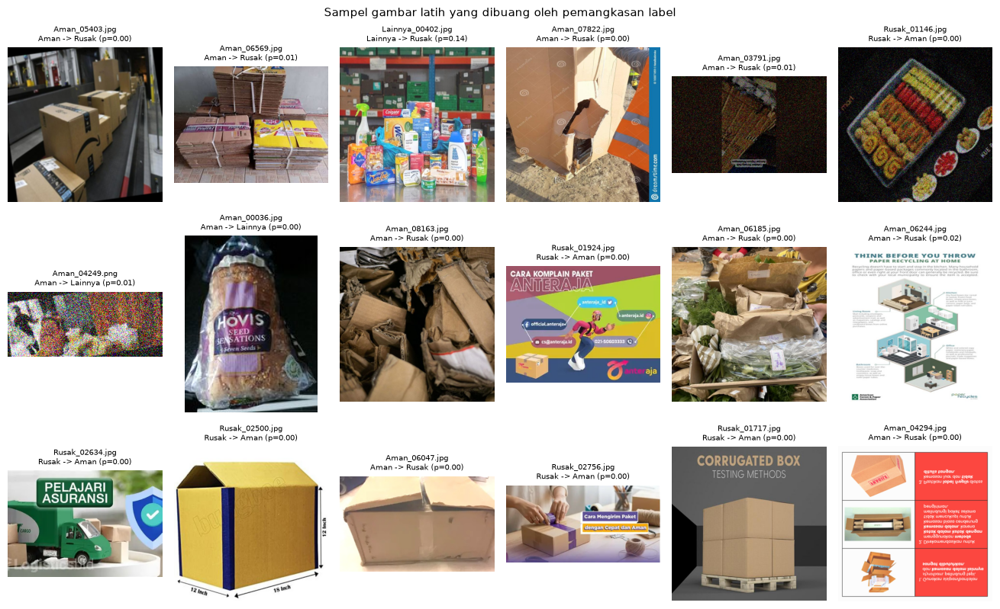

In [43]:
if not CFG.INFERENCE:
    n_rows = len(train_df)
    artifact = (~train_df['clean'].to_numpy(dtype=bool)).astype(int)
    P = np.where(np.isnan(oof), 0.0, oof)
    rows = np.arange(n_rows)

    thr = np.ones((2, NUM_CLASSES))
    for s in (0, 1):
        for c in range(NUM_CLASSES):
            m = active & (artifact == s) & (y_active == c)
            if m.sum():
                thr[s, c] = P[m, c].mean()
    print('Ambang per kelas (baris: bersih, berjejak):')
    print(pd.DataFrame(thr, index=['bersih', 'berjejak'], columns=CFG.CLASSES).round(3).to_string())

    own_p = P[rows, y_active]
    eligible = P >= thr[artifact]
    eligible[rows, y_active] = False
    other_score = np.where(eligible, P, -1.0)
    other = other_score.argmax(1)
    candidate = active & (own_p < thr[artifact, y_active]) & eligible.any(1)
    margin = other_score.max(1) - own_p

    prune = np.zeros(n_rows, dtype=bool)
    if CFG.CLEAN_CONFIDENT:
        for s in (0, 1):
            for c in range(NUM_CLASSES):
                cell = active & (artifact == s) & (y_active == c)
                idx = np.where(candidate & cell)[0]
                cap = int(CL_FRAC * cell.sum())
                idx = idx[np.argsort(-margin[idx])][:cap]
                prune[idx] = True
    train_df.loc[prune, 'status'] = 'buang_label_ragu'

    flag_table = pd.crosstab(pd.Series(np.array(CFG.CLASSES)[y_active[prune]], name='label saat ini'), pd.Series(np.array(CFG.CLASSES)[other[prune]], name='kelas usulan probe'))
    print(f'Kandidat: {int(candidate.sum())} | dibuang: {int(prune.sum())} | berjejak augmentasi di antara yang dibuang: {artifact[prune].mean():.2f} (di seluruh data: {artifact[active].mean():.2f})')
    print(flag_table.to_string())

    show = np.where(prune)[0]
    show = show[np.random.default_rng(CFG.SEED).permutation(len(show))[:18]]
    if len(show):
        show_grid(train_df['path'].to_numpy()[show].tolist(),
                  [f"{train_df['name'].iloc[i]}\n{CFG.CLASSES[y_active[i]]} -> {CFG.CLASSES[other[i]]} (p={own_p[i]:.2f})" for i in show],
                  'Sampel gambar latih yang dibuang oleh pemangkasan label', cols=6, save_as='pruned_samples.png')
else:
    print('INFERENCE = True, aturan 3 dilewati')

> ### Insights
> Dari 922 kandidat, aturan 3 membuang 246 baris: 198 berlabel Aman, 42 Rusak, dan 6 Lainnya. Di antara 6.872 pasangan gambar kembar dengan berkas berbeda, laju selisih label turun dari 0,0292 menjadi 0,0290 setelah aturan 1 dan 2. Perkiraan *noise* acak sebesar 0,0145 menghasilkan batas pemangkasan 0,0217 (2,17%) per kelompok.
>
> Baris berjejak augmentasi mencakup 39% dari yang dibuang, sama dengan porsinya pada seluruh data aktif (39%). Hasil ini tidak menunjukkan pemangkasan yang tidak proporsional terhadap gambar berjejak augmentasi.

---

## Hasil Pembersihan

Baris yang dibuang dikeluarkan dari tabel latih, dan label baris yang dipindah diganti dengan label barunya. Fold validasi dipertahankan karena grup gambar mirip tidak berubah. Seluruh keputusan disimpan ke `cleaning_log.csv`.

In [44]:
if not CFG.INFERENCE:
    log = train_df[['name', 'label_orig', 'source', 'status', 'y_clean']].copy()
    log['label_baru'] = np.array(CFG.CLASSES)[log['y_clean']]
    log.loc[log['status'].str.startswith('buang'), 'label_baru'] = ''
    log.to_csv(CFG.OUTPUT_DIR / 'cleaning_log.csv', index=False)

    before = train_df['label_orig'].value_counts().reindex(CFG.CLASSES)
    keep_mask = train_df['status'].isin(['simpan', 'pindah_sumber'])
    train_df = train_df[keep_mask].reset_index(drop=True)
    train_df['y'] = train_df['y_clean'].astype(int)
    train_df['label'] = np.array(CFG.CLASSES)[train_df['y']]
    after = train_df['label'].value_counts().reindex(CFG.CLASSES)

    summary = pd.DataFrame({'sebelum': before, 'sesudah': after, 'selisih': after - before})
    print(summary.to_string())
    print()
    print(log['status'].value_counts().to_string())
    fold_check = pd.crosstab(train_df['fold'], train_df['label']).reindex(columns=CFG.CLASSES, fill_value=0)
    print()
    print(fold_check.to_string())
    assert (fold_check.values > 0).all(), 'ada fold tanpa salah satu kelas'
else:
    print('INFERENCE = True, penerapan hasil pembersihan dilewati')

         sebelum  sesudah  selisih
Aman        8532     8965      433
Rusak       2616     1917     -699
Lainnya      423      417       -6

status
simpan               10646
pindah_sumber          653
buang_label_ragu       246
buang_konflik_md5       26

label  Aman  Rusak  Lainnya
fold                       
0      1819    378       83
1      1794    396       85
2      1699    394       82
3      1808    395       83
4      1845    354       84


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pelatihan <a name="8"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Utilitas Pelatihan

Bobot alpha pada *focal loss* memakai akar kebalikan frekuensi kelas dan ditambahkan di atas *sampler* berbobot agar kelas Lainnya tetap berpengaruh. Epoch pertama hanya melatih *head*, dan setelah itu blok yang dibuka ikut dilatih dengan *learning rate* yang meluruh per blok dari norm akhir ke bawah (`LAYER_DECAY`), dengan jadwal *cosine* sepanjang `EPOCHS`.

EMA (*exponential moving average*) menyimpan rata-rata eksponensial bobot setelah setiap langkah optimizer, $\theta_{EMA} \leftarrow d\,\theta_{EMA} + (1-d)\,\theta$. Peluruhan $d$ dinaikkan bertahap lewat $\min(d_{maks}, (1+t)/(10+t))$, sehingga EMA tidak tertahan pada bobot awal di langkah-langkah pertama.

In [45]:
def build_criterion(y):
    counts = np.bincount(y, minlength=NUM_CLASSES)
    alpha = torch.tensor(1.0 / np.sqrt(np.maximum(counts, 1)), dtype=torch.float32, device=DEVICE)
    alpha = alpha / alpha.mean()
    return FocalLossWithSmoothing(NUM_CLASSES, alpha, CFG.FOCAL_GAMMA, CFG.LABEL_SMOOTHING)

def set_backbone_trainable(model, trainable):
    names = set(model.tunable_names)
    for n, p in model.named_parameters():
        if n in names:
            p.requires_grad = trainable

def make_optimizer(model):
    prefix = 'backbone.' + model.block_name + '.'
    params = dict(model.named_parameters())
    by_scale = {}
    for n in model.tunable_names:
        if n.startswith(prefix):
            depth_from_top = model.n_blocks - int(n[len(prefix):].split('.', 1)[0])
        else:
            depth_from_top = 0
        by_scale.setdefault(depth_from_top, []).append(params[n])
    groups = [{'params': ps, 'lr': CFG.BACKBONE_LR * CFG.LAYER_DECAY ** k} for k, ps in sorted(by_scale.items())]
    head = [p for n, p in model.named_parameters() if not n.startswith('backbone.')]
    groups.append({'params': head, 'lr': CFG.HEAD_LR})
    return torch.optim.AdamW(groups, weight_decay=CFG.WEIGHT_DECAY)

class TrainableEMA:
    def __init__(self, model, decay):
        params = dict(model.named_parameters())
        self.shadow = {n: params[n].detach().clone().float() for n in model.save_names}
        self.pairs = [(self.shadow[n], params[n]) for n in model.save_names]
        self.decay = decay
        self.steps = 0

    @torch.no_grad()
    def update(self):
        self.steps += 1
        d = min(self.decay, (1 + self.steps) / (10 + self.steps))
        for shadow, p in self.pairs:
            shadow.mul_(d).add_(p.detach().float(), alpha=1 - d)

    def state(self):
        return {n: t.detach().cpu().clone() for n, t in self.shadow.items()}

@torch.no_grad()
def copy_into(model, state):
    params = dict(model.named_parameters())
    for n, t in state.items():
        params[n].copy_(t)

def run_train_epoch(model, loader, criterion, optimizer, scaler=None, ema=None):
    model.train()
    losses, all_t, all_p = [], [], []
    optimizer.zero_grad(set_to_none=True)
    for step, (x, t) in enumerate(tqdm(loader, desc='train', leave=False), start=1):
        x = x.to(DEVICE, non_blocking=True)
        t = t.to(DEVICE, non_blocking=True)
        with autocast_ctx():
            logits = model(x)
        loss = criterion(logits.float(), t)
        scaled = loss / CFG.GRAD_ACCUM_STEPS
        if scaler is not None:
            scaler.scale(scaled).backward()
        else:
            scaled.backward()
        if step % CFG.GRAD_ACCUM_STEPS == 0 or step == len(loader):
            if scaler is not None:
                scaler.step(optimizer)
                scaler.update()
            else:
                optimizer.step()
            optimizer.zero_grad(set_to_none=True)
            if ema is not None:
                ema.update()
        losses.append(loss.item())
        all_t.extend(t.cpu().numpy().tolist())
        all_p.extend(logits.argmax(1).detach().cpu().numpy().tolist())
    return {'loss': float(np.mean(losses)), 'macro_f1': macro_f1(all_t, all_p)}

def collect_logits(model, loader, use_tta):
    model.eval()
    out = []
    with torch.no_grad(), autocast_ctx():
        for batch in tqdm(loader, desc='collect', leave=False):
            x = (batch[0] if isinstance(batch, (list, tuple)) else batch).to(DEVICE, non_blocking=True)
            logits = model(x).float()
            if use_tta:
                logits = 0.5 * (logits + model(torch.flip(x, dims=[3])).float())
            out.append(logits.cpu())
    return torch.cat(out)

def save_checkpoint(state, path, **extra):
    torch.save({
        'state_dict': state,
        'classes': CFG.CLASSES,
        'model_id': CFG.MODEL_ID,
        'unfreeze_last_n': CFG.UNFREEZE_LAST_N,
        'img_size': CFG.IMG_SIZE,
        'image_mean': CFG.MEAN,
        'image_std': CFG.STD,
        'head': {'name': CFG.HEAD_NAME, 'feature_dropout': CFG.FEATURE_DROPOUT_P, 'head_dropout': CFG.HEAD_DROPOUT_P, 'msd_samples': CFG.MSD_SAMPLES},
        'use_ema': CFG.USE_EMA,
        'use_tta': CFG.USE_TTA,
        **extra,
    }, path)
    print(f'Checkpoint disimpan: {path} ({path.stat().st_size / 1024 ** 3:.2f} GB)')

---

## Diagnostik Pembobotan Kelas

*Sampler* berbobot dan alpha pada *focal loss* sama-sama menaikkan pengaruh kelas kecil, sehingga bila keduanya penuh efeknya berlipat. Tabel berikut menghitung dari jumlah baris latih fold 0 tiga hal untuk beberapa nilai `SAMPLER_POWER`: porsi gambar per kelas yang ditarik *sampler*, berapa kali tiap gambar kelas itu terlihat dalam satu epoch, dan beban gradien efektif per kelas setelah dikalikan alpha. Pangkat 1,0 adalah *sampler* berbobot penuh, 0,0 adalah pengambilan acak biasa.

In [46]:
if not CFG.INFERENCE:
    diag_y = train_df.loc[train_df['fold'] != 0, 'y'].to_numpy()
    diag_n = np.bincount(diag_y, minlength=NUM_CLASSES).astype(float)
    diag_alpha = 1.0 / np.sqrt(diag_n)
    diag_alpha = diag_alpha / diag_alpha.mean()

    diag_rows = []
    for power in sorted({1.0, CFG.SAMPLER_POWER, 0.0}, reverse=True):
        share = diag_n ** (1 - power)
        share = share / share.sum()
        views = share * diag_n.sum() / diag_n
        effective = share * diag_alpha
        effective = effective / effective.sum()
        for c, name in enumerate(CFG.CLASSES):
            diag_rows.append({'pangkat': power, 'kelas': name, 'baris': int(diag_n[c]), 'porsi tarikan': share[c], 'tampilan per epoch': views[c], 'tampilan seluruh epoch': views[c] * CFG.EPOCHS, 'beban gradien': effective[c]})
    diag_table = pd.DataFrame(diag_rows).set_index(['pangkat', 'kelas'])
    print(diag_table.round(3).to_string())
    print('Pangkat yang dipakai:', CFG.SAMPLER_POWER)
else:
    print('INFERENCE = True, diagnostik pembobotan dilewati')

                 baris  porsi tarikan  tampilan per epoch  tampilan seluruh epoch  beban gradien
pangkat kelas                                                                                   
1.0     Aman      7146          0.333               0.421                   4.207          0.129
        Rusak     1539          0.333               1.953                  19.534          0.277
        Lainnya    334          0.333               9.001                  90.010          0.595
0.5     Aman      7146          0.595               0.751                   7.511          0.333
        Rusak     1539          0.276               1.619                  16.186          0.333
        Lainnya    334          0.129               3.474                  34.744          0.333
0.0     Aman      7146          0.792               1.000                  10.000          0.595
        Rusak     1539          0.171               1.000                  10.000          0.276
        Lainnya    334        

> ### Insights
> Pada perkiraan jumlah baris setelah aturan 1 dan 2, yaitu sekitar 7.330 Aman, 1.567 Rusak, dan 338 Lainnya di fold latih, *sampler* penuh bersama alpha memberi kelas Lainnya sekitar 60% beban gradien padahal kelas itu hanya 3,7% data.

---

## Validasi Silang 5 Fold dengan EMA

In [47]:
if not CFG.INFERENCE:
    y_all = train_df['y'].to_numpy()
    paths_all = train_df['path'].to_numpy()
    folds_all = train_df['fold'].to_numpy()
    oof_logits = torch.full((len(train_df), NUM_CLASSES), float('nan'))
    histories, fold_rows = [], []

    for fold in range(CFG.N_FOLDS):
        tr_idx = np.where(folds_all != fold)[0]
        va_idx = np.where(folds_all == fold)[0]
        print(f'\n=== Fold {fold} | latih {len(tr_idx)} | validasi {len(va_idx)} ===')

        seed_everything(CFG.SEED + fold)
        load_trainable(model, PRETRAINED_STATE)
        criterion = build_criterion(y_all[tr_idx])
        optimizer = make_optimizer(model)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG.EPOCHS)
        scaler = torch.amp.GradScaler('cuda') if USE_AMP and CFG.AMP_DTYPE == 'float16' else None
        ema = TrainableEMA(model, CFG.EMA_DECAY) if CFG.USE_EMA else None
        val_loader = make_loader(paths_all[va_idx], y_all[va_idx], train=False)
        iter(val_loader)
        train_loader = make_loader(paths_all[tr_idx], y_all[tr_idx], train=True)
        y_va = torch.from_numpy(y_all[va_idx])

        best_f1, best_epoch, best_logits, rows = -1.0, 0, None, []
        for epoch in range(1, CFG.EPOCHS + 1):
            set_backbone_trainable(model, epoch > CFG.FREEZE_BACKBONE_EPOCHS)
            t0 = time.time()
            tr_m = run_train_epoch(model, train_loader, criterion, optimizer, scaler, ema)
            scheduler.step()

            if ema is not None:
                backup = {n: p.detach().clone() for n, p in model.named_parameters() if n in ema.shadow}
                copy_into(model, ema.shadow)
            va_logits = collect_logits(model, val_loader, CFG.USE_TTA)
            va_loss = float(criterion(va_logits.to(DEVICE), y_va.to(DEVICE)).item())
            va_pred = va_logits.argmax(1).numpy()
            va_f1 = macro_f1(y_all[va_idx], va_pred)
            va_acc = float(accuracy_score(y_all[va_idx], va_pred))
            if va_f1 > best_f1 or not CFG.SELECT_BEST_EPOCH:
                best_f1, best_epoch, best_logits = va_f1, epoch, va_logits
            if ema is not None:
                copy_into(model, backup)
                del backup

            rows.append({'fold': fold, 'epoch': epoch, 'train_loss': tr_m['loss'], 'train_f1': tr_m['macro_f1'], 'val_loss': va_loss, 'val_f1': va_f1, 'val_acc': va_acc})
            print(f"fold {fold} epoch {epoch:02d}/{CFG.EPOCHS} | train loss {tr_m['loss']:.4f} f1 {tr_m['macro_f1']:.4f} | val{' EMA' if ema is not None else ''} loss {va_loss:.4f} f1 {va_f1:.4f} acc {va_acc:.4f} | {time.time() - t0:.0f}s")

        oof_logits[va_idx] = best_logits
        histories.append(pd.DataFrame(rows))
        fold_rows.append({'fold': fold, 'epoch_terbaik': best_epoch, 'val_macro_f1': best_f1, 'n_val': len(va_idx)})

        del optimizer, scheduler, scaler, ema, train_loader, val_loader, best_logits
        gc.collect()
        torch.cuda.empty_cache()

    history = pd.concat(histories, ignore_index=True)
    history.to_csv(CFG.OUTPUT_DIR / 'history.csv', index=False)
    fold_summary = pd.DataFrame(fold_rows)
    fold_summary.to_csv(CFG.OUTPUT_DIR / 'fold_summary.csv', index=False)
    print()
    print(fold_summary.round(4).to_string(index=False))
    print(f"Rata-rata Macro F1 validasi per fold: {fold_summary['val_macro_f1'].mean():.4f} +/- {fold_summary['val_macro_f1'].std():.4f}")
else:
    print('INFERENCE = True, pelatihan 5 fold dilewati')


=== Fold 0 | latih 9019 | validasi 2280 ===
fold 0 epoch 01/10 | train loss 0.1708 f1 0.7213 | val EMA loss 0.1395 f1 0.7683 acc 0.9035 | 237s
fold 0 epoch 02/10 | train loss 0.0983 f1 0.8336 | val EMA loss 0.0867 f1 0.8324 acc 0.9297 | 392s
fold 0 epoch 03/10 | train loss 0.0657 f1 0.8888 | val EMA loss 0.0689 f1 0.8709 acc 0.9455 | 364s
fold 0 epoch 04/10 | train loss 0.0459 f1 0.9236 | val EMA loss 0.0530 f1 0.9035 acc 0.9589 | 379s
fold 0 epoch 05/10 | train loss 0.0341 f1 0.9426 | val EMA loss 0.0489 f1 0.9160 acc 0.9640 | 363s
fold 0 epoch 06/10 | train loss 0.0277 f1 0.9529 | val EMA loss 0.0408 f1 0.9272 acc 0.9686 | 392s
fold 0 epoch 07/10 | train loss 0.0242 f1 0.9627 | val EMA loss 0.0393 f1 0.9313 acc 0.9703 | 370s
fold 0 epoch 08/10 | train loss 0.0206 f1 0.9665 | val EMA loss 0.0373 f1 0.9340 acc 0.9714 | 365s
fold 0 epoch 09/10 | train loss 0.0188 f1 0.9726 | val EMA loss 0.0351 f1 0.9364 acc 0.9724 | 367s
fold 0 epoch 10/10 | train loss 0.0186 f1 0.9750 | val EMA loss 

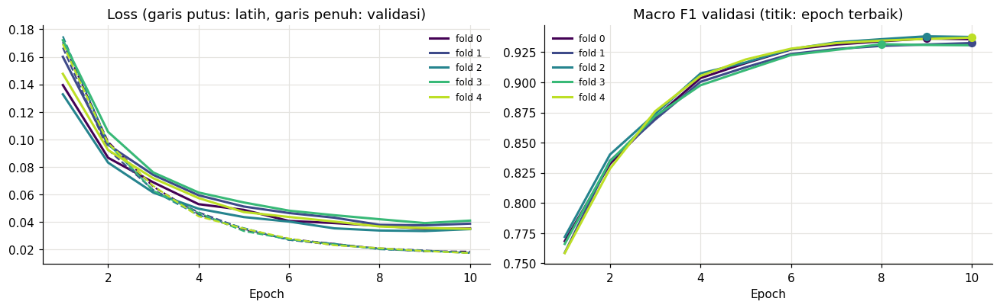

In [48]:
if not CFG.INFERENCE:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    fold_colors = plt.cm.viridis(np.linspace(0, 0.9, CFG.N_FOLDS))
    for fold, h in history.groupby('fold'):
        axes[0].plot(h['epoch'], h['train_loss'], color=fold_colors[fold], linewidth=1.5, linestyle='--')
        axes[0].plot(h['epoch'], h['val_loss'], color=fold_colors[fold], linewidth=2, label=f'fold {fold}')
        axes[1].plot(h['epoch'], h['val_f1'], color=fold_colors[fold], linewidth=2, label=f'fold {fold}')
        best = fold_summary.loc[fold_summary['fold'] == fold, 'epoch_terbaik'].iloc[0]
        axes[1].scatter([best], [h.loc[h['epoch'] == best, 'val_f1'].iloc[0]], color=fold_colors[fold], s=40, zorder=3)
    axes[0].set_title('Loss (garis putus: latih, garis penuh: validasi)')
    axes[1].set_title('Macro F1 validasi (titik: epoch terbaik)')
    for ax in axes:
        ax.set_xlabel('Epoch')
        ax.legend(frameon=False, fontsize=8)
        style_axis(ax, grid_axis='both')
    fig.tight_layout()
    fig.savefig(CFG.FIG_DIR / 'training_curves.png', dpi=110)
    plt.show()
else:
    print('INFERENCE = True, kurva pelatihan dilewati')

---

## Pelatihan Ulang pada 100% Data

In [49]:
if not CFG.INFERENCE:
    oof_f1 = macro_f1(y_all, oof_logits.argmax(1).numpy())
    FULL_EPOCHS = CFG.FULL_EPOCHS or int(np.ceil(np.median(fold_summary['epoch_terbaik'])))
    print(f"Epoch terbaik per fold: {fold_summary['epoch_terbaik'].tolist()} -> FULL_EPOCHS = {FULL_EPOCHS}")
    print(f'Pelatihan ulang pada {len(train_df)} gambar | Macro F1 OOF validasi silang: {oof_f1:.4f}')

    seed_everything(CFG.SEED)
    load_trainable(model, PRETRAINED_STATE)
    criterion = build_criterion(y_all)
    optimizer = make_optimizer(model)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(CFG.EPOCHS, FULL_EPOCHS))
    scaler = torch.amp.GradScaler('cuda') if USE_AMP and CFG.AMP_DTYPE == 'float16' else None
    ema = TrainableEMA(model, CFG.EMA_DECAY) if CFG.USE_EMA else None
    train_loader = make_loader(paths_all, y_all, train=True)

    full_rows = []
    for epoch in range(1, FULL_EPOCHS + 1):
        set_backbone_trainable(model, epoch > CFG.FREEZE_BACKBONE_EPOCHS)
        t0 = time.time()
        tr_m = run_train_epoch(model, train_loader, criterion, optimizer, scaler, ema)
        scheduler.step()
        full_rows.append({'epoch': epoch, 'train_loss': tr_m['loss'], 'train_f1': tr_m['macro_f1']})
        print(f"full epoch {epoch:02d}/{FULL_EPOCHS} | train loss {tr_m['loss']:.4f} f1 {tr_m['macro_f1']:.4f} | {time.time() - t0:.0f}s")

    final_state = ema.state() if ema is not None else trainable_state(model)
    save_checkpoint(final_state, CKPT_PATH, full_epochs=int(FULL_EPOCHS), n_train=int(len(train_df)), oof_macro_f1=float(oof_f1), fold_val_macro_f1=[float(v) for v in fold_summary['val_macro_f1']])
    pd.DataFrame(full_rows).to_csv(CFG.OUTPUT_DIR / 'history_full.csv', index=False)

    del optimizer, scheduler, scaler, ema, train_loader, final_state
    gc.collect()
    torch.cuda.empty_cache()
else:
    print('INFERENCE = True, pelatihan ulang 100% dilewati')

Epoch terbaik per fold: [9, 10, 9, 8, 10] -> FULL_EPOCHS = 9
Pelatihan ulang pada 11299 gambar | Macro F1 OOF validasi silang: 0.9352
full epoch 01/9 | train loss 0.1658 f1 0.7316 | 278s
full epoch 02/9 | train loss 0.0907 f1 0.8463 | 441s
full epoch 03/9 | train loss 0.0609 f1 0.8998 | 446s
full epoch 04/9 | train loss 0.0432 f1 0.9324 | 426s
full epoch 05/9 | train loss 0.0326 f1 0.9487 | 448s
full epoch 06/9 | train loss 0.0263 f1 0.9596 | 437s
full epoch 07/9 | train loss 0.0222 f1 0.9675 | 426s
full epoch 08/9 | train loss 0.0194 f1 0.9721 | 436s
full epoch 09/9 | train loss 0.0178 f1 0.9764 | 436s
Checkpoint disimpan: output/dinov3_vit7b16_cleaned/checkpoints/dinov3_vit7b16_cleaned.pt (3.75 GB)


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Inferensi dan Submisi <a name="9"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Muat Checkpoint

Load model DINOv3 yang telah dilatih

In [ ]:
if CFG.INFERENCE and CFG.CHECKPOINT_URL and not CKPT_PATH.exists():
    gdown.download(CFG.CHECKPOINT_URL, str(CKPT_PATH), quiet=False)

assert CKPT_PATH.exists(), f'checkpoint tidak ditemukan: {CKPT_PATH.resolve()}'
print(f'{CKPT_PATH} ({CKPT_PATH.stat().st_size / 1024 ** 3:.2f} GB)')

output/dinov3_vit7b16_cleaned/checkpoints/dinov3_vit7b16_cleaned.pt (3.75 GB)


In [51]:
def load_checkpoint(path, model):
    ckpt = torch.load(path, map_location='cpu', weights_only=True)
    expected = {'model_id': CFG.MODEL_ID, 'img_size': CFG.IMG_SIZE, 'unfreeze_last_n': CFG.UNFREEZE_LAST_N, 'classes': CFG.CLASSES}
    for key, value in expected.items():
        assert ckpt[key] == value, f'{path.name} dilatih dengan {key}={ckpt[key]}, setelan saat ini {value}'
    assert np.allclose(ckpt['image_mean'], CFG.MEAN) and np.allclose(ckpt['image_std'], CFG.STD), f'{path.name} memakai normalisasi lain'
    load_trainable(model, ckpt['state_dict'])
    meta = {k: v for k, v in ckpt.items() if k != 'state_dict'}
    del ckpt
    gc.collect()
    return meta

---

## Evaluasi Out-of-Fold

Macro F1 OOF: 0.9352
              precision    recall  f1-score   support

        Aman      0.983     0.983     0.983      8965
       Rusak      0.932     0.929     0.930      1917
     Lainnya      0.892     0.892     0.892       417

    accuracy                          0.971     11299
   macro avg      0.936     0.935     0.935     11299
weighted avg      0.971     0.971     0.971     11299



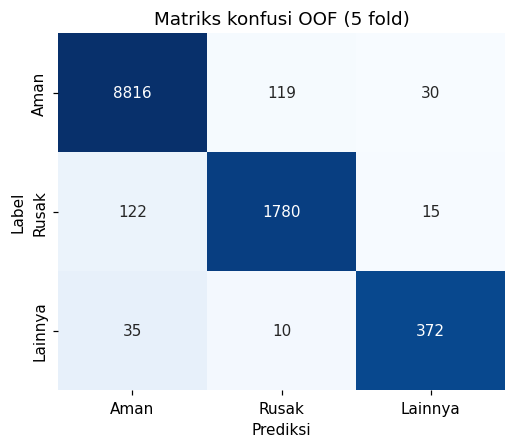

In [52]:
if not CFG.INFERENCE:
    oof_probs = torch.softmax(oof_logits, dim=1).numpy()
    oof_pred = oof_probs.argmax(1)
    print(f'Macro F1 OOF: {macro_f1(y_all, oof_pred):.4f}')
    print(classification_report(y_all, oof_pred, target_names=CFG.CLASSES, digits=3))

    cm = confusion_matrix(y_all, oof_pred, labels=list(range(NUM_CLASSES)))
    cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(4.8, 4.2))
    sns.heatmap(cm_norm, annot=cm, fmt='d', cmap='Blues', xticklabels=CFG.CLASSES, yticklabels=CFG.CLASSES, cbar=False, ax=ax)
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Label')
    ax.set_title('Matriks konfusi OOF (5 fold)')
    fig.tight_layout()
    fig.savefig(CFG.FIG_DIR / 'confusion_matrix_oof.png', dpi=110)
    plt.show()

    oof_out = train_df[['name', 'label', 'source', 'fold']].copy()
    for k, c in enumerate(CFG.CLASSES):
        oof_out[f'p_{c}'] = oof_probs[:, k]
    oof_out['pred'] = np.array(CFG.CLASSES)[oof_pred]
    oof_out.to_csv(CFG.OUTPUT_DIR / 'oof_predictions.csv', index=False)
else:
    print('INFERENCE = True, evaluasi OOF dilewati')

---

## Preprocessing Data Uji

Format asli: {'JPEG': 2315, 'WEBP': 597, 'PNG': 145}
Mode warna : {'RGB': 2953, 'RGBA': 101, 'P': 3}
tensor uji shape=(64, 3, 320, 320) min=-2.118 max=2.640 mean=[0.806 0.806 0.83 ]


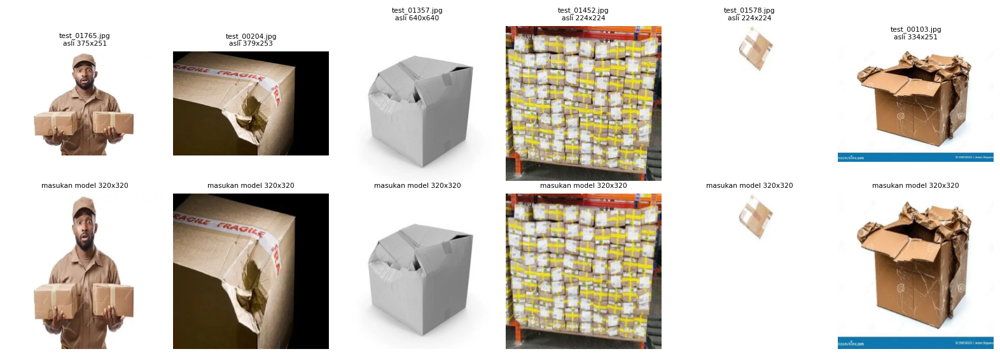

In [53]:
def header_info(path):
    with Image.open(path) as im:
        return im.size[0], im.size[1], im.mode, im.format

with ThreadPoolExecutor(max(4, CFG.NUM_WORKERS)) as ex:
    info = list(tqdm(ex.map(header_info, infer_df['path']), total=len(infer_df), desc='header uji'))
infer_df['width'] = [i[0] for i in info]
infer_df['height'] = [i[1] for i in info]
infer_df['mode'] = [i[2] for i in info]
infer_df['format'] = [i[3] for i in info]
infer_df['source'] = infer_df['width'].astype(str) + 'x' + infer_df['height'].astype(str)
print('Format asli:', infer_df['format'].value_counts().to_dict())
print('Mode warna :', infer_df['mode'].value_counts().to_dict())

check = infer_df.sample(min(64, len(infer_df)), random_state=CFG.SEED)
check_batch = torch.stack([EVAL_TF(load_rgb(p, max_side=2 * CFG.IMG_SIZE)) for p in check['path']])
lo = min((0 - m) / s for m, s in zip(CFG.MEAN, CFG.STD))
hi = max((1 - m) / s for m, s in zip(CFG.MEAN, CFG.STD))
assert check_batch.shape[1:] == (3, CFG.IMG_SIZE, CFG.IMG_SIZE) and check_batch.dtype == torch.float32
assert torch.isfinite(check_batch).all() and check_batch.min() >= lo - 1e-4 and check_batch.max() <= hi + 1e-4
print(f'tensor uji shape={tuple(check_batch.shape)} min={check_batch.min():.3f} max={check_batch.max():.3f} mean={check_batch.mean((0, 2, 3)).numpy().round(3)}')

show = check.head(6)
fig, axes = plt.subplots(2, len(show), figsize=(len(show) * 2.4, 5.2), squeeze=False)
for k, (_, r) in enumerate(show.iterrows()):
    im = load_rgb(r['path'], max_side=2 * CFG.IMG_SIZE)
    axes[0, k].imshow(im)
    axes[0, k].set_title(f"{r['name']}\nasli {r['source']}", fontsize=7)
    axes[1, k].imshow(denormalize(EVAL_TF(im)))
    axes[1, k].set_title(f'masukan model {CFG.IMG_SIZE}x{CFG.IMG_SIZE}', fontsize=7)
for ax in axes.ravel():
    ax.axis('off')
fig.tight_layout()
fig.savefig(CFG.FIG_DIR / 'test_preprocess_check.png', dpi=110, bbox_inches='tight')
plt.show()

---

## Inferensi Test Set

In [54]:
test_loader = DataLoader(PackageDataset(infer_df['path'].tolist(), EVAL_TF), batch_size=CFG.EVAL_BATCH_SIZE, shuffle=False, num_workers=CFG.NUM_WORKERS, pin_memory=False)

meta = load_checkpoint(CKPT_PATH, model)
test_logits = collect_logits(model, test_loader, CFG.USE_TTA)
test_probs = torch.softmax(test_logits, dim=1).numpy()
test_pred = test_probs.argmax(1)
np.save(CFG.OUTPUT_DIR / 'test_probs.npy', test_probs)
print(f'Inferensi selesai: {len(test_pred)} gambar, TTA cermin: {CFG.USE_TTA}')

Inferensi selesai: 3057 gambar, TTA cermin: True


---

## Pembuatan Berkas Submisi

In [55]:
submission = pd.DataFrame({'filename': infer_df['name'], 'label': np.array(CFG.CLASSES)[test_pred]})
assert len(submission) == len(infer_df) and submission['filename'].is_unique, 'jumlah atau nama baris submisi tidak sesuai'
assert not submission.isna().any().any(), 'terdapat nilai kosong pada submisi'
assert submission['label'].isin(CFG.CLASSES).all(), 'label tidak valid'
submission.to_csv(CFG.OUTPUT_DIR / 'submission.csv', index=False)

pred_out = infer_df[['name', 'source']].copy()
for k, c in enumerate(CFG.CLASSES):
    pred_out[f'p_{c}'] = test_probs[:, k]
pred_out['pred'] = submission['label'].to_numpy()
pred_out.to_csv(CFG.OUTPUT_DIR / 'test_predictions.csv', index=False)

share = submission['label'].value_counts().reindex(CFG.CLASSES).fillna(0).astype(int)
print(pd.DataFrame({'jumlah': share, 'porsi': (share / share.sum()).round(3)}).to_string())
print('Submisi disimpan ke:', CFG.OUTPUT_DIR / 'submission.csv')

         jumlah  porsi
label                 
Aman       2224  0.728
Rusak       735  0.240
Lainnya      98  0.032
Submisi disimpan ke: output/dinov3_vit7b16_cleaned/submission.csv


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pasca-Analisis <a name="10"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">



## Analisis Kesalahan OOF

Kesalahan OOF: 331 dari 11299
pred     Aman  Lainnya  Rusak
label                        
Aman        0       30    119
Lainnya    35        0     10
Rusak     122       15      0
         salah  total  porsi_salah
source                            
640x640     88   2198        0.040
512x512     58   2473        0.023
675x900      8    499        0.016
679x900      4     40        0.100
150x200      4     42        0.095
224x224      3    252        0.012
416x416      3    298        0.010
267x267      2     97        0.021
225x225      2     28        0.071
208x251      2      3        0.667


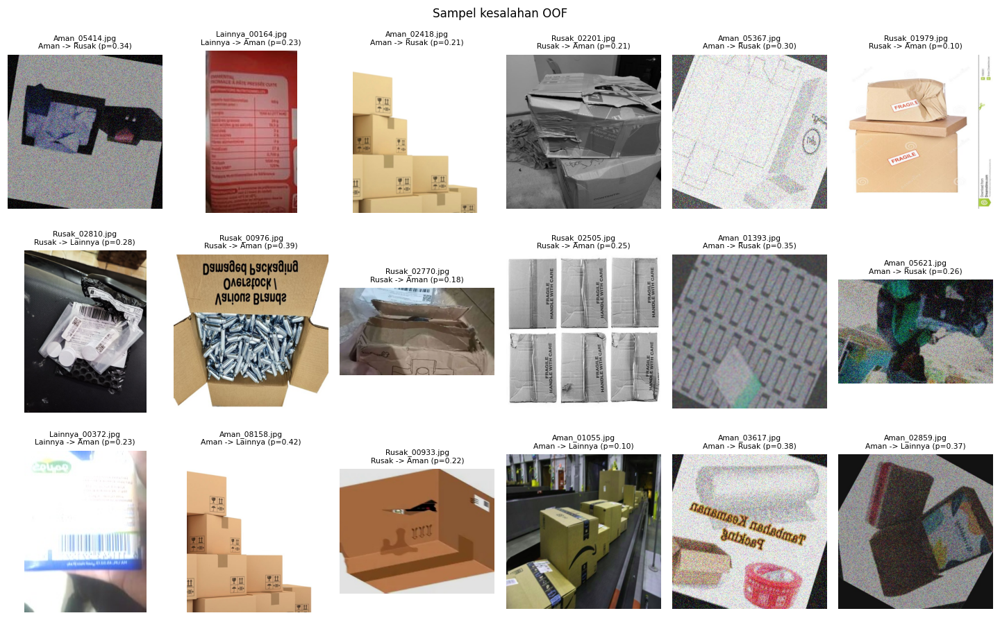

In [56]:
if not CFG.INFERENCE:
    errors = oof_out[oof_out['pred'] != oof_out['label']].copy()
    errors['p_label'] = [oof_probs[i, CLASS_TO_ID[l]] for i, l in zip(errors.index, errors['label'])]
    print(f'Kesalahan OOF: {len(errors)} dari {len(oof_out)}')
    print(pd.crosstab(errors['label'], errors['pred']).to_string())

    err_by_source = errors['source'].value_counts().head(10).rename('salah').to_frame()
    err_by_source['total'] = oof_out['source'].value_counts().reindex(err_by_source.index)
    err_by_source['porsi_salah'] = (err_by_source['salah'] / err_by_source['total']).round(3)
    print(err_by_source.to_string())

    show = errors.sample(min(18, len(errors)), random_state=CFG.SEED)
    if len(show):
        path_map = dict(zip(train_df['name'], train_df['path']))
        show_grid(show['name'].map(path_map).tolist(), [f"{r['name']}\n{r['label']} -> {r['pred']} (p={r['p_label']:.2f})" for _, r in show.iterrows()],
                  'Sampel kesalahan OOF', cols=6, save_as='oof_errors.png')
else:
    print('INFERENCE = True, analisis kesalahan OOF dilewati')

---

## Ringkasan Berkas Keluaran

Seluruh keluaran berada di folder `output/<RUN_NAME>`. Bobot model akhir disimpan dalam satu berkas `<RUN_NAME>.pt` di `CHECKPOINT_DIR`, dan `submission.csv` berada di akar folder keluaran.

In [57]:
for p in sorted(set(CFG.OUTPUT_DIR.rglob('*')) | set(CFG.CHECKPOINT_DIR.glob('*.pt'))):
    if p.is_file():
        print(f'{p.stat().st_size / 1024 ** 2:9.2f} MB  {p}')

  3841.17 MB  output/dinov3_vit7b16_cleaned/checkpoints/dinov3_vit7b16_cleaned.pt
     0.59 MB  output/dinov3_vit7b16_cleaned/cleaning_log.csv
     0.02 MB  output/dinov3_vit7b16_cleaned/figures/class_distribution.png
     0.02 MB  output/dinov3_vit7b16_cleaned/figures/confusion_matrix_oof.png
     0.60 MB  output/dinov3_vit7b16_cleaned/figures/label_conflicts.png
     0.03 MB  output/dinov3_vit7b16_cleaned/figures/offline_augmentation.png
     0.90 MB  output/dinov3_vit7b16_cleaned/figures/offline_augmentation_examples.png
     1.36 MB  output/dinov3_vit7b16_cleaned/figures/oof_errors.png
     1.97 MB  output/dinov3_vit7b16_cleaned/figures/preprocess_augmentation_check.png
     0.46 MB  output/dinov3_vit7b16_cleaned/figures/preprocess_loader_check.png
     0.42 MB  output/dinov3_vit7b16_cleaned/figures/preprocess_resize_check.png
     1.12 MB  output/dinov3_vit7b16_cleaned/figures/pruned_samples.png
     0.64 MB  output/dinov3_vit7b16_cleaned/figures/regroup_pairs.png
     0.63 MB  ou

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Thanks! <a name=""></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">